# Entrega 4: Descriptores y Clasificación — Visión Artificial

**Asignatura:** Introducción a la Visión Artificial (Grupo 190202024-4)  
**Docente:** Paula Alejandra Ortiz Santana  
**Pipeline 100 % automático y reproducible** basado exclusivamente en procesamiento digital de imágenes clásico (`OpenCV`, `NumPy`) y clasificadores sobre descriptores artesanales (`scikit-learn`). **No se utilizan redes convolucionales (CNN), modelos preentrenados ni servicios de IA.**

### Estructura del notebook
1. Configuración inicial y carga de librerías.
2. Exploración de la base de datos (`propia` vs. `scraping`, balance y mosaico).
3. Pipeline automático de procesamiento (5 bloques obligatorios + evidencia antes/después + alternativa descartada).
4. Extracción de 18 descriptores (Color, Forma y Textura) estrictamente dentro de la máscara.
5. Clasificación (Heurístico vs. KNN / SVM), evaluación en prueba, análisis de errores y comparación `propia` vs. `scraping`.
6. Exportación de métricas reales a `resultados/metricas.json`.

In [1]:
import json
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

import config

warnings.filterwarnings("ignore")

# Configuración visual global para figuras legibles y de alta resolución
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.titlesize": 12,
        "axes.labelsize": 11,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
        "legend.fontsize": 10,
    }
)

config.RESULTADOS_DIR.mkdir(parents=True, exist_ok=True)
config.FIGURAS_DIR.mkdir(parents=True, exist_ok=True)

PALETA_CLASES = {config.CLASE_0: "#1b9e77", config.CLASE_1: "#d95f02"}
PALETA_ORIGEN = {"propia": "#2b6cb0", "scraping": "#e69f00"}

print(f"Proyecto : {config.TITULO_PROYECTO}")
print(f"Clase 0  : {config.CLASE_0} ({config.CLASE_0_NOMBRE})")
print(f"Clase 1  : {config.CLASE_1} ({config.CLASE_1_NOMBRE})")
print(f"Dataset  : {config.DATASET_DIR}")
print(f"Figuras  : {config.FIGURAS_DIR}")

Proyecto : Sistema de Visión Artificial para Clasificación de Esmeraldas Colombianas (Esmeralda suelta vs. Esmeralda montada) en Valoración Gemológica Asistida (CIGEM)
Clase 0  : esmeralda_suelta (Esmeralda suelta)
Clase 1  : esmeralda_montada (Esmeralda montada)
Dataset  : C:\Users\Juan.Escobar\Desktop\Vision artificial\dataset
Figuras  : C:\Users\Juan.Escobar\Desktop\Vision artificial\resultados\figuras


---
## 1. Exploración de la base de datos
Se carga `dataset/dataset_origen.csv`, se verifica la integridad de los archivos y se analiza el conteo final por clase y por origen (`propia` vs. `scraping`), así como el balance entre clases.

=== Conteo de imágenes por clase y origen ===


origen,propia,scraping,Total
clase_nombre,,,
Esmeralda montada,27,148,175
Esmeralda suelta,45,135,180
Total,72,283,355



Total imágenes válidas: 355 | Balance min/max: 0.972
Diagnóstico de balance: Clases bien balanceadas (razón >= 0.85).


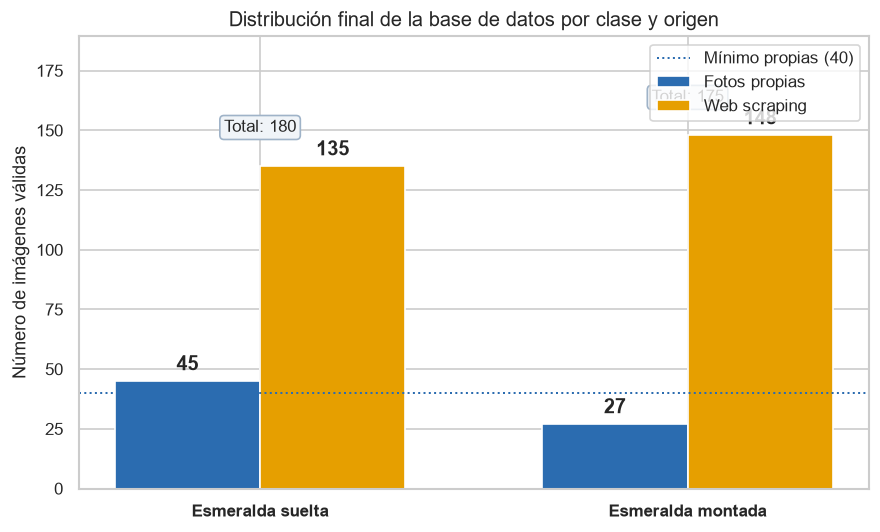

In [2]:
if not config.DATASET_CSV.exists():
    raise FileNotFoundError(
        f"No se encontró {config.DATASET_CSV}. Ejecute primero 'python scraping_y_curacion.py'."
    )

df_meta = pd.read_csv(config.DATASET_CSV)
df_meta["filepath"] = df_meta["filename"].apply(lambda x: str(config.DATASET_DIR / x))
df_meta["existe"] = df_meta["filepath"].apply(lambda p: Path(p).is_file())

faltantes = int((~df_meta["existe"]).sum())
if faltantes > 0:
    print(f"[Aviso] Se omitieron {faltantes} registros cuyos archivos no existen en disco.")
    df_meta = df_meta[df_meta["existe"]].reset_index(drop=True)

df_meta["clase_nombre"] = df_meta["clase"].map(config.CLASES_NOMBRES)

# Tabla cruzada por clase y origen
tabla_conteos = pd.crosstab(
    df_meta["clase_nombre"], df_meta["origen"], margins=True, margins_name="Total"
)
for col in ["propia", "scraping"]:
    if col not in tabla_conteos.columns:
        tabla_conteos[col] = 0
tabla_conteos = tabla_conteos[["propia", "scraping", "Total"]]
print("=== Conteo de imágenes por clase y origen ===")
display(tabla_conteos)

conteos_clase = df_meta["clase"].value_counts().to_dict()
c0_n = int(conteos_clase.get(config.CLASE_0, 0))
c1_n = int(conteos_clase.get(config.CLASE_1, 0))
ratio_balance = round(min(c0_n, c1_n) / max(c0_n, c1_n), 4) if max(c0_n, c1_n) > 0 else 0.0
print(f"\nTotal imágenes válidas: {len(df_meta)} | Balance min/max: {ratio_balance:.3f}")
if ratio_balance >= 0.85:
    print("Diagnóstico de balance: Clases bien balanceadas (razón >= 0.85).")
else:
    print("Diagnóstico de balance: Existe desbalance moderado; se usará partición estratificada.")

# Gráfica de barras por clase y origen
fig, ax = plt.subplots(figsize=(7.5, 4.6))
orden_clases = [config.CLASE_0_NOMBRE, config.CLASE_1_NOMBRE]
x = np.arange(len(orden_clases))
width = 0.34

vals_prop = [
    int(((df_meta["clase_nombre"] == cn) & (df_meta["origen"] == "propia")).sum())
    for cn in orden_clases
]
vals_scrap = [
    int(((df_meta["clase_nombre"] == cn) & (df_meta["origen"] == "scraping")).sum())
    for cn in orden_clases
]

b1 = ax.bar(x - width / 2, vals_prop, width, label="Fotos propias", color=PALETA_ORIGEN["propia"])
b2 = ax.bar(x + width / 2, vals_scrap, width, label="Web scraping", color=PALETA_ORIGEN["scraping"])

for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(
            f"{int(h)}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontweight="bold",
        )

for idx, cn in enumerate(orden_clases):
    tot = vals_prop[idx] + vals_scrap[idx]
    ax.text(
        x[idx],
        max(vals_prop[idx], vals_scrap[idx]) + max(8, tot * 0.08),
        f"Total: {tot}",
        ha="center",
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="#f0f4f8", edgecolor="#9fb3c8"),
    )

ax.axhline(
    config.MIN_PROPIAS_RECOMENDADAS,
    color="#2b6cb0",
    linestyle=":",
    linewidth=1.2,
    label=f"Mínimo propias ({config.MIN_PROPIAS_RECOMENDADAS})",
)
ax.set_xticks(x)
ax.set_xticklabels(orden_clases, fontweight="bold")
ax.set_ylabel("Número de imágenes válidas")
ax.set_title("Distribución final de la base de datos por clase y origen")
ax.set_ylim(0, max(vals_prop + vals_scrap + [60]) * 1.28)
ax.legend(loc="upper right", frameon=True)
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig01_distribucion_dataset.png", bbox_inches="tight")
plt.show()

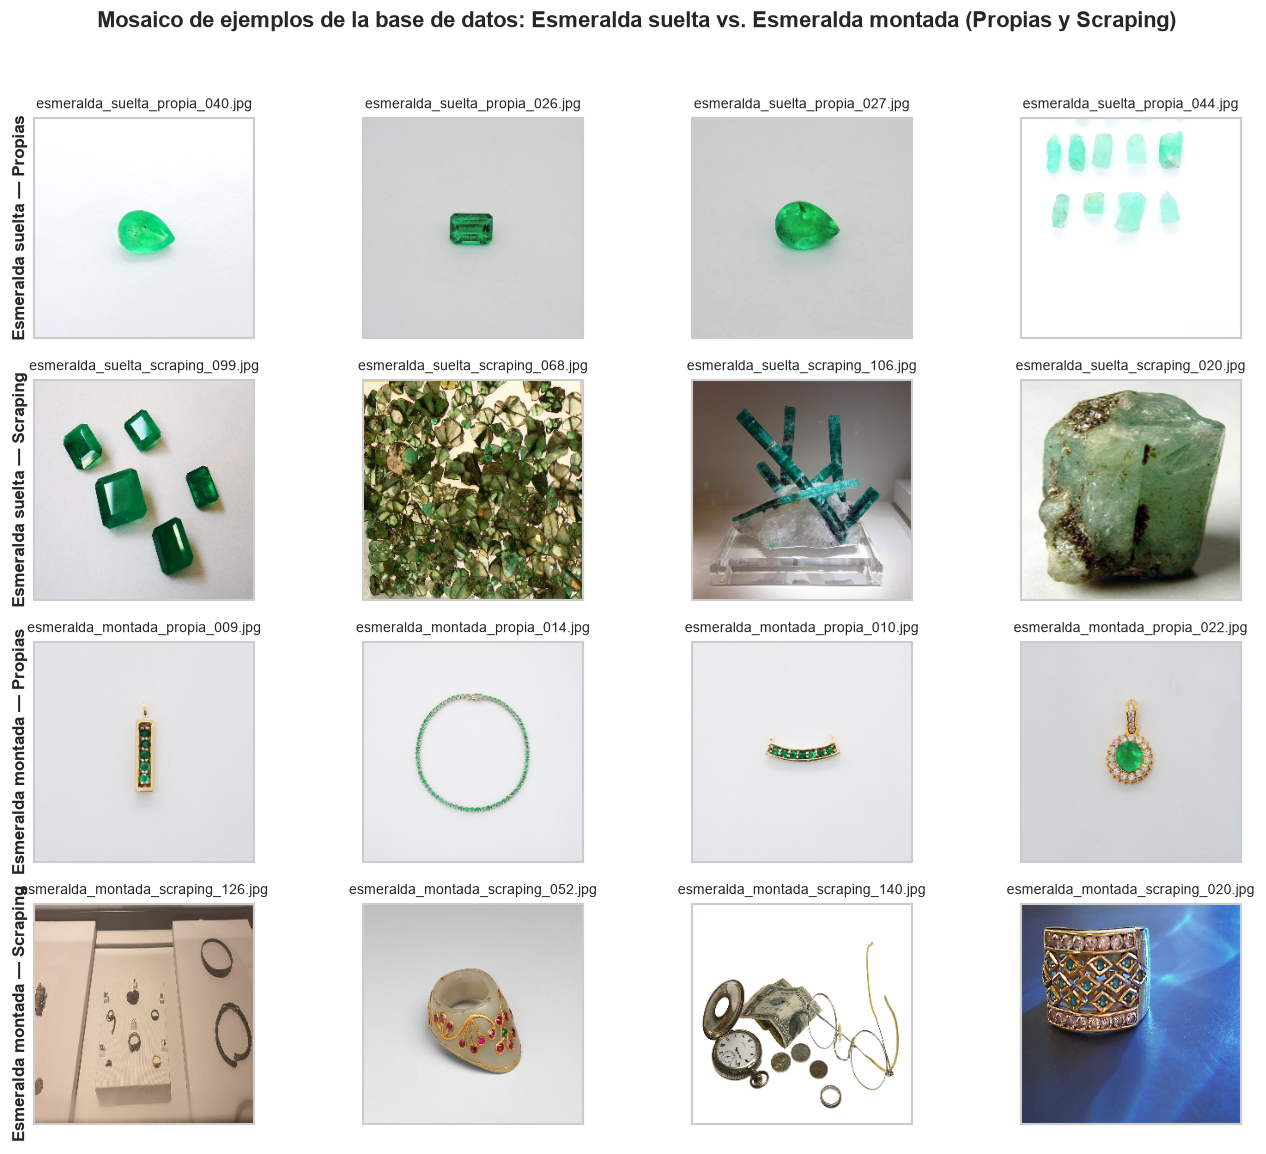

In [3]:
# Figura mosaico con ejemplos de cada clase (propias y scraping)
rng = np.random.default_rng(config.RANDOM_STATE)
filas_espec = [
    (config.CLASE_0, "propia", f"{config.CLASE_0_NOMBRE} — Propias"),
    (config.CLASE_0, "scraping", f"{config.CLASE_0_NOMBRE} — Scraping"),
    (config.CLASE_1, "propia", f"{config.CLASE_1_NOMBRE} — Propias"),
    (config.CLASE_1, "scraping", f"{config.CLASE_1_NOMBRE} — Scraping"),
]

n_cols = 4
fig, axes = plt.subplots(len(filas_espec), n_cols, figsize=(11.5, 9.5))
fig.suptitle(
    f"Mosaico de ejemplos de la base de datos: {config.CLASE_0_NOMBRE} vs. {config.CLASE_1_NOMBRE} (Propias y Scraping)",
    fontsize=13,
    fontweight="bold",
    y=0.995,
)

for r, (clase, origen, titulo_fila) in enumerate(filas_espec):
    sub = df_meta[(df_meta["clase"] == clase) & (df_meta["origen"] == origen)]
    muestras = (
        sub.sample(n=min(n_cols, len(sub)), random_state=config.RANDOM_STATE)
        if len(sub) > 0
        else sub
    )
    for c in range(n_cols):
        ax = axes[r, c]
        if c < len(muestras):
            row = muestras.iloc[c]
            img = cv2.imread(row["filepath"])
            if img is not None:
                img_rgb = cv2.cvtColor(cv2.resize(img, (256, 256)), cv2.COLOR_BGR2RGB)
                ax.imshow(img_rgb)
                ax.set_title(Path(row["filename"]).name, fontsize=8.5)
        else:
            ax.text(0.5, 0.5, "Sin muestra", ha="center", va="center", fontsize=9, color="gray")
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(titulo_fila, fontsize=10, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.975])
fig.savefig(config.FIGURAS_DIR / "fig02_mosaico_ejemplos.png", bbox_inches="tight")
plt.show()

---
## 2. Pipeline automático de procesamiento y segmentación
Se aplica el **mismo pipeline automático** a todas las imágenes integrando los cinco bloques obligatorios del semestre:
1. **Intensidad e histograma:** Redimensionamiento uniforme (`256x256`) + **CLAHE** sobre el canal de luminancia `L*` (CIELab) para compensar diferencias de iluminación entre fotos de estudio/celular e imágenes de scraping sin alterar el tono cromático.
2. **Filtrado espacial:** **Filtro Gaussiano (`5x5`, `sigma=1.0`)** para atenuar ruido del sensor y suavizar reflejos especulares puntuales en las facetas.
3. **Modelos de color:** Conversión simultánea a **HSV** (matiz `H` y saturación `S` separados de brillo `V`) y **CIELab** (ejes perceptuales verde–rojo `a*` y azul–amarillo `b*` independientes de luminancia `L*`).
4. **Máscaras y segmentación:** Estimación automática del color del borde (fondo) en CIELab -> cálculo de distancia cromática perceptual $\Delta E$ al fondo combinada con saturación `S` -> umbralización automática de **Otsu**.
5. **Morfología matemática:** **Apertura** (`5x5` elíptica) para eliminar ruido aislado + **Cierre** (`11x11` elíptica) para unir facetas fragmentadas por brillos especulares + selección del contorno principal (combinando área y centralidad) con rellenado completo de huecos internos.

In [4]:
def redimensionar_estandar(img_bgr: np.ndarray, size: int = config.IMG_SIZE) -> np.ndarray:
    """Redimensiona la imagen a tamaño cuadrado estándar (256x256)."""
    interp = cv2.INTER_AREA if min(img_bgr.shape[:2]) >= size else cv2.INTER_CUBIC
    return cv2.resize(img_bgr, (size, size), interpolation=interp)


def aplicar_clahe_lab(img_bgr: np.ndarray) -> np.ndarray:
    """Bloque 1 (Intensidad/Histograma): CLAHE únicamente sobre el canal L* en CIELab."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l_chan, a_chan, b_chan = cv2.split(lab)
    clahe = cv2.createCLAHE(
        clipLimit=config.CLAHE_CLIP_LIMIT, tileGridSize=config.CLAHE_TILE_GRID
    )
    l_eq = clahe.apply(l_chan)
    lab_eq = cv2.merge((l_eq, a_chan, b_chan))
    return cv2.cvtColor(lab_eq, cv2.COLOR_LAB2BGR)


def aplicar_filtro_gaussiano(img_bgr: np.ndarray) -> np.ndarray:
    """Bloque 2 (Filtrado espacial): Filtro Gaussiano 5x5 para reducir ruido y destellos."""
    return cv2.GaussianBlur(img_bgr, config.GAUSSIAN_KSIZE, config.GAUSSIAN_SIGMA)


def segmentar_otsu_lab_hsv(img_bgr_filt: np.ndarray):
    """
    Bloques 3 y 4 (Modelos de color + Máscaras/Segmentación):
    - Estima el color de fondo con la mediana del marco perimetral (12 px) en CIELab.
    - Calcula el mapa de distancia perceptual Delta-E al fondo y lo combina con
      el canal de saturación S (HSV), ya que las piedras preciosas suelen tener
      mayor saturación y fuerte contraste cromático respecto al fondo.
    - Aplica umbralización automática de Otsu.
    """
    hsv = cv2.cvtColor(img_bgr_filt, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(img_bgr_filt, cv2.COLOR_BGR2LAB)

    h, w = lab.shape[:2]
    borde = 12
    mascara_borde = np.zeros((h, w), dtype=bool)
    mascara_borde[:borde, :] = True
    mascara_borde[-borde:, :] = True
    mascara_borde[:, :borde] = True
    mascara_borde[:, -borde:] = True

    lab_f = lab.astype(np.float32)
    bg_lab = np.median(lab_f[mascara_borde], axis=0)

    # Distancia perceptual ponderando canales cromáticos (a*, b*) sobre luminancia (L*)
    diff = lab_f - bg_lab
    delta_e = np.sqrt(0.45 * (diff[:, :, 0] ** 2) + 1.0 * (diff[:, :, 1] ** 2) + 1.0 * (diff[:, :, 2] ** 2))
    delta_e_norm = cv2.normalize(delta_e, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    s_chan = hsv[:, :, 1]
    score_map = cv2.addWeighted(delta_e_norm, 0.65, s_chan, 0.35, 0)

    _, mask_otsu = cv2.threshold(score_map, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # Salvaguarda automática: si la máscara invadió casi todo el borde, probar solo Delta-E
    frac_borde = float(np.mean(mask_otsu[mascara_borde] > 0))
    frac_area = float(np.mean(mask_otsu > 0))
    if frac_borde > 0.65 or frac_area < 0.015 or frac_area > 0.92:
        _, mask_alt = cv2.threshold(delta_e_norm, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        if float(np.mean(mask_alt[mascara_borde] > 0)) > 0.65:
            mask_alt = cv2.bitwise_not(mask_alt)
        area_alt = float(np.mean(mask_alt > 0))
        if 0.015 <= area_alt <= 0.90:
            mask_otsu = mask_alt

    return hsv, lab, score_map, mask_otsu


def limpiar_mascara_morfologia(mask_otsu: np.ndarray):
    """
    Bloque 5 (Morfología matemática):
    - Apertura (elimina ruido aislado en el fondo).
    - Cierre (rellena brechas y brillos especulares en las facetas).
    - Selección automática del contorno principal (área ponderada por cercanía al centro)
      y rellenado total de huecos internos.
    """
    h, w = mask_otsu.shape[:2]
    img_area = float(h * w)
    cx_img, cy_img = w / 2.0, h / 2.0
    max_dist = float(np.hypot(cx_img, cy_img))

    k_open = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, config.MORPH_OPEN_KSIZE)
    k_close = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, config.MORPH_CLOSE_KSIZE)

    mask_open = cv2.morphologyEx(mask_otsu, cv2.MORPH_OPEN, k_open)
    mask_close = cv2.morphologyEx(mask_open, cv2.MORPH_CLOSE, k_close)

    contornos, _ = cv2.findContours(mask_close, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    mejor_contorno = None
    mejor_puntaje = -1.0

    for cnt in contornos:
        area = cv2.contourArea(cnt)
        if area < 0.008 * img_area:
            continue
        m = cv2.moments(cnt)
        if m["m00"] > 0:
            cx = m["m10"] / m["m00"]
            cy = m["m01"] / m["m00"]
        else:
            x, y, bw, bh = cv2.boundingRect(cnt)
            cx, cy = x + bw / 2.0, y + bh / 2.0
        dist_norm = float(np.hypot(cx - cx_img, cy - cy_img)) / max_dist
        puntaje = area * (1.0 - 0.55 * dist_norm)
        if puntaje > mejor_puntaje:
            mejor_puntaje = puntaje
            mejor_contorno = cnt

    mask_final = np.zeros((h, w), dtype=np.uint8)
    if mejor_contorno is None:
        # Salvaguarda final: elipse central si la imagen careciera de contornos válidos
        cv2.ellipse(mask_final, (w // 2, h // 2), (w // 4, h // 4), 0, 0, 360, 255, -1)
        cnts_fb, _ = cv2.findContours(mask_final, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        mejor_contorno = cnts_fb[0]
    else:
        # Dibujar contorno relleno elimina automáticamente todos los huecos internos
        cv2.drawContours(mask_final, [mejor_contorno], -1, 255, thickness=cv2.FILLED)

    return mask_open, mask_close, mask_final, mejor_contorno


def procesar_imagen_completo(img_bgr: np.ndarray) -> dict:
    """Ejecuta el pipeline completo sobre una imagen BGR y retorna etapas intermedias."""
    orig_256 = redimensionar_estandar(img_bgr, config.IMG_SIZE)
    clahe_bgr = aplicar_clahe_lab(orig_256)
    gauss_bgr = aplicar_filtro_gaussiano(clahe_bgr)
    hsv, lab, score_map, mask_otsu = segmentar_otsu_lab_hsv(gauss_bgr)
    mask_open, mask_close, mask_final, contorno = limpiar_mascara_morfologia(mask_otsu)
    seg_bgr = cv2.bitwise_and(gauss_bgr, gauss_bgr, mask=mask_final)
    return {
        "orig_256": orig_256,
        "clahe_bgr": clahe_bgr,
        "gauss_bgr": gauss_bgr,
        "hsv": hsv,
        "lab": lab,
        "score_map": score_map,
        "mask_otsu": mask_otsu,
        "mask_open": mask_open,
        "mask_close": mask_close,
        "mask_final": mask_final,
        "contorno": contorno,
        "seg_bgr": seg_bgr,
    }


def segmentar_alternativa_descartada(img_bgr: np.ndarray) -> np.ndarray:
    """
    Alternativa descartada para comparación con evidencia:
    Umbral fijo (T=127 invertido) en escala de grises sin CLAHE, sin modelos de color
    y sin morfología matemática.
    """
    orig_256 = redimensionar_estandar(img_bgr, config.IMG_SIZE)
    gris = cv2.cvtColor(orig_256, cv2.COLOR_BGR2GRAY)
    _, mask_fija = cv2.threshold(gris, 127, 255, cv2.THRESH_BINARY_INV)
    return mask_fija


print("Funciones del pipeline automático cargadas correctamente.")

Funciones del pipeline automático cargadas correctamente.


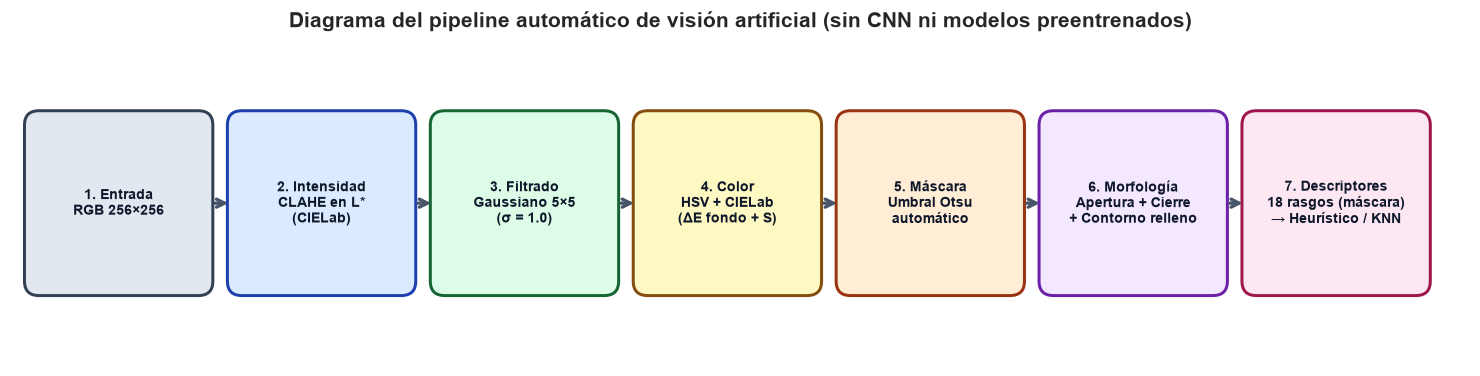

In [5]:
# Figura 3: Diagrama técnico del pipeline completo
fig, ax = plt.subplots(figsize=(12.5, 3.3))
ax.set_xlim(0, 14)
ax.set_ylim(0, 3.2)
ax.axis("off")

bloques = [
    (0.2, "1. Entrada\nRGB 256×256", "#e2e8f0", "#334155"),
    (2.15, "2. Intensidad\nCLAHE en L*\n(CIELab)", "#dbeafe", "#1e40af"),
    (4.1, "3. Filtrado\nGaussiano 5×5\n(σ = 1.0)", "#dcfce7", "#166534"),
    (6.05, "4. Color\nHSV + CIELab\n(ΔE fondo + S)", "#fef9c3", "#854d0e"),
    (8.0, "5. Máscara\nUmbral Otsu\nautomático", "#ffedd5", "#9a3412"),
    (9.95, "6. Morfología\nApertura + Cierre\n+ Contorno relleno", "#f3e8ff", "#6b21a8"),
    (11.9, "7. Descriptores\n18 rasgos (máscara)\n→ Heurístico / KNN", "#fce7f3", "#9d174d"),
]

for i, (x0, texto, fc, ec) in enumerate(bloques):
    box = mpatches.FancyBboxPatch(
        (x0, 0.75),
        1.65,
        1.65,
        boxstyle="round,pad=0.08,rounding_size=0.14",
        facecolor=fc,
        edgecolor=ec,
        linewidth=1.8,
    )
    ax.add_patch(box)
    ax.text(
        x0 + 0.825,
        1.575,
        texto,
        ha="center",
        va="center",
        fontsize=8.6,
        fontweight="bold",
        color="#0f172a",
    )
    if i < len(bloques) - 1:
        ax.annotate(
            "",
            xy=(bloques[i + 1][0] - 0.04, 1.575),
            xytext=(x0 + 1.72, 1.575),
            arrowprops=dict(arrowstyle="->", lw=2.0, color="#475569"),
        )

ax.set_title(
    "Diagrama del pipeline automático de visión artificial (sin CNN ni modelos preentrenados)",
    fontsize=12.5,
    fontweight="bold",
    pad=6,
)
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig03_diagrama_pipeline.png", bbox_inches="tight")
plt.show()

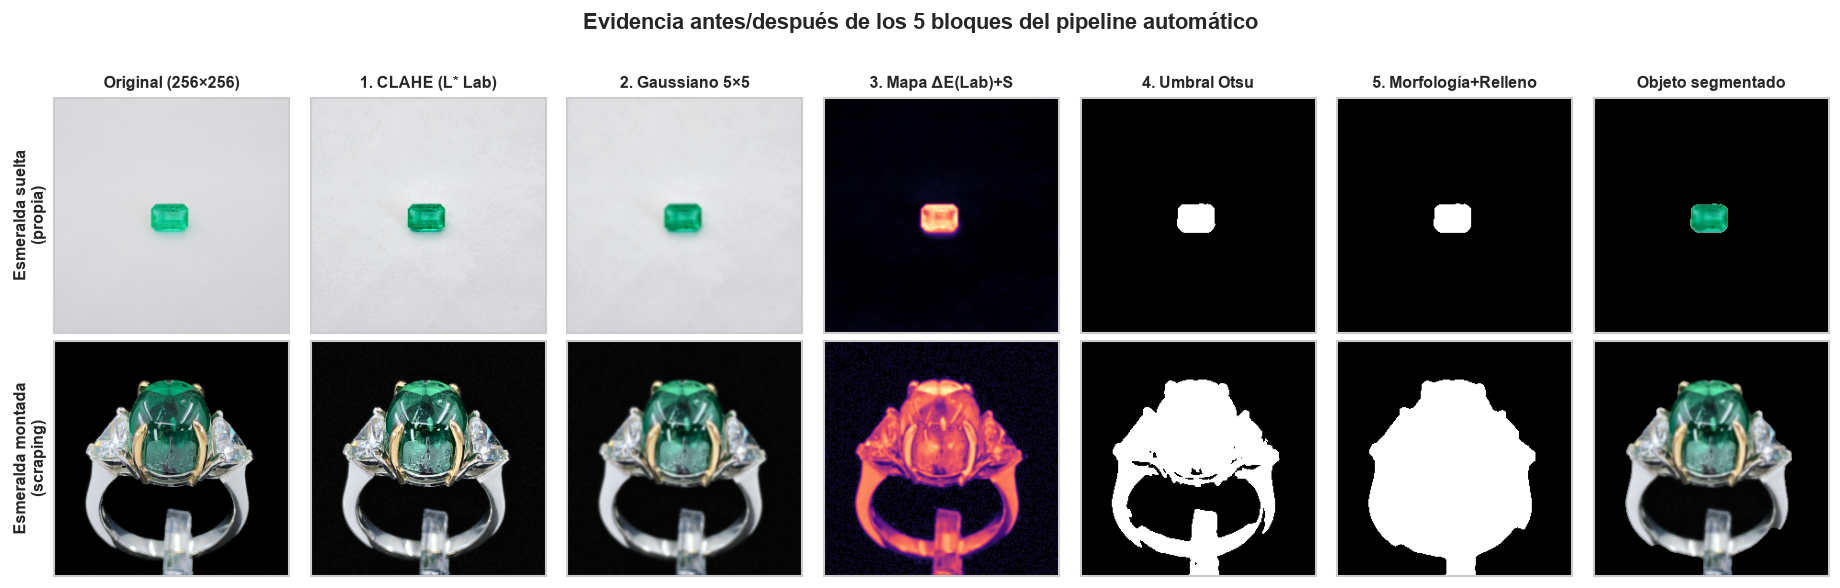

In [6]:
# Figura 4: Evidencia antes/después de cada bloque del pipeline
def elegir_muestra(df, clase, origen_pref):
    sub = df[(df["clase"] == clase) & (df["origen"] == origen_pref)]
    if len(sub) == 0:
        sub = df[df["clase"] == clase]
    return sub.iloc[min(2, len(sub) - 1)]


ejemplos_pipe = [
    elegir_muestra(df_meta, config.CLASE_0, "propia"),
    elegir_muestra(df_meta, config.CLASE_1, "scraping"),
]

titulos_etapas = [
    "Original (256×256)",
    "1. CLAHE (L* Lab)",
    "2. Gaussiano 5×5",
    "3. Mapa ΔE(Lab)+S",
    "4. Umbral Otsu",
    "5. Morfología+Relleno",
    "Objeto segmentado",
]

fig, axes = plt.subplots(2, 7, figsize=(15.5, 4.9))
fig.suptitle(
    "Evidencia antes/después de los 5 bloques del pipeline automático",
    fontsize=13,
    fontweight="bold",
    y=1.01,
)

for r, row in enumerate(ejemplos_pipe):
    img_bgr = cv2.imread(row["filepath"])
    proc = procesar_imagen_completo(img_bgr)
    etapas = [
        (cv2.cvtColor(proc["orig_256"], cv2.COLOR_BGR2RGB), None),
        (cv2.cvtColor(proc["clahe_bgr"], cv2.COLOR_BGR2RGB), None),
        (cv2.cvtColor(proc["gauss_bgr"], cv2.COLOR_BGR2RGB), None),
        (proc["score_map"], "magma"),
        (proc["mask_otsu"], "gray"),
        (proc["mask_final"], "gray"),
        (cv2.cvtColor(proc["seg_bgr"], cv2.COLOR_BGR2RGB), None),
    ]
    for c, (im, cmap) in enumerate(etapas):
        ax = axes[r, c]
        ax.imshow(im, cmap=cmap)
        if r == 0:
            ax.set_title(titulos_etapas[c], fontsize=9.5, fontweight="bold")
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(
                f"{row['clase_nombre']}\n({row['origen']})",
                fontsize=9.5,
                fontweight="bold",
            )

plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig04_antes_despues_bloques.png", bbox_inches="tight")
plt.show()

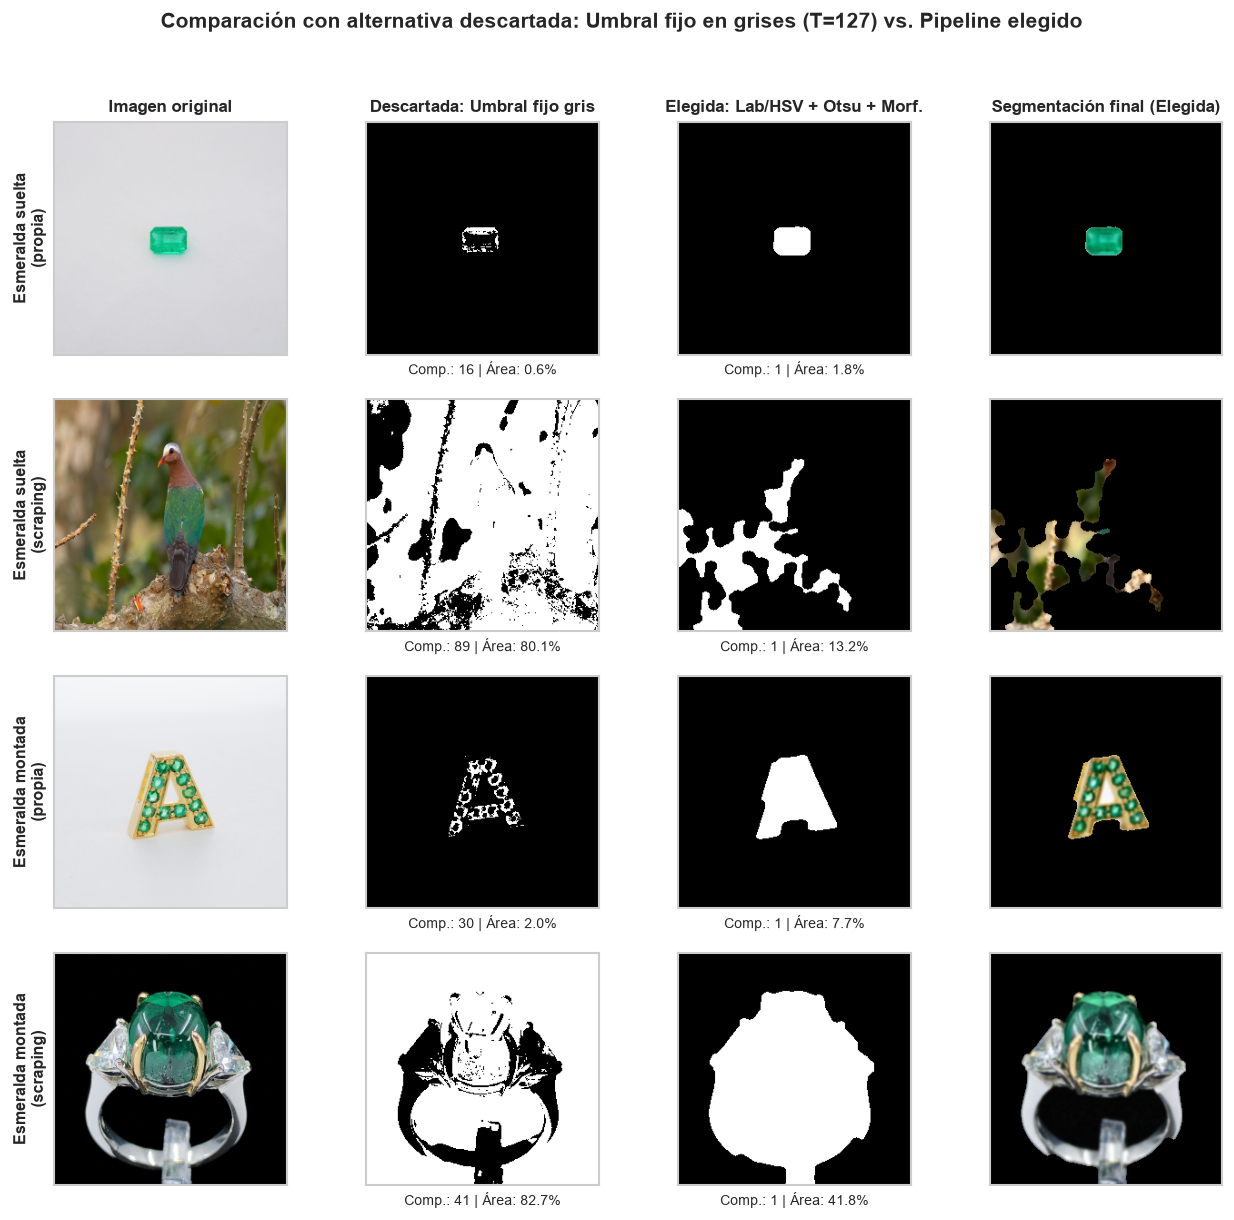

Evidencia cuantitativa (alternativa descartada vs. pipeline elegido):


,imagen,componentes_umbral_fijo,componentes_pipeline_elegido,area_pct_umbral_fijo,area_pct_pipeline_elegido
0,esmeralda_suelta_propia_003.jpg,16,1,0.6,1.8
1,esmeralda_suelta_scraping_003.jpg,89,1,80.1,13.2
2,esmeralda_montada_propia_003.jpg,30,1,2.0,7.7
3,esmeralda_montada_scraping_003.jpg,41,1,82.7,41.8


In [7]:
# Figura 5: Comparación con alternativa descartada (Umbral fijo gris T=127 vs. Pipeline elegido)
muestras_comp = [
    elegir_muestra(df_meta, config.CLASE_0, "propia"),
    elegir_muestra(df_meta, config.CLASE_0, "scraping"),
    elegir_muestra(df_meta, config.CLASE_1, "propia"),
    elegir_muestra(df_meta, config.CLASE_1, "scraping"),
]

fig, axes = plt.subplots(4, 4, figsize=(11.0, 10.2))
fig.suptitle(
    "Comparación con alternativa descartada: Umbral fijo en grises (T=127) vs. Pipeline elegido",
    fontsize=12.5,
    fontweight="bold",
    y=0.995,
)

cols_comp = [
    "Imagen original",
    "Descartada: Umbral fijo gris",
    "Elegida: Lab/HSV + Otsu + Morf.",
    "Segmentación final (Elegida)",
]

comp_stats = []
for r, row in enumerate(muestras_comp):
    img_bgr = cv2.imread(row["filepath"])
    proc = procesar_imagen_completo(img_bgr)
    mask_desc = segmentar_alternativa_descartada(img_bgr)

    # Medir número de componentes conexas (fragmentación) como evidencia cuantitativa
    n_comp_desc = cv2.connectedComponents(mask_desc)[0] - 1
    n_comp_eleg = cv2.connectedComponents(proc["mask_final"])[0] - 1
    comp_stats.append(
        {
            "imagen": Path(row["filename"]).name,
            "componentes_umbral_fijo": int(n_comp_desc),
            "componentes_pipeline_elegido": int(n_comp_eleg),
            "area_pct_umbral_fijo": round(100.0 * float(np.mean(mask_desc > 0)), 1),
            "area_pct_pipeline_elegido": round(100.0 * float(np.mean(proc["mask_final"] > 0)), 1),
        }
    )

    imgs_fila = [
        (cv2.cvtColor(proc["orig_256"], cv2.COLOR_BGR2RGB), None),
        (mask_desc, "gray"),
        (proc["mask_final"], "gray"),
        (cv2.cvtColor(proc["seg_bgr"], cv2.COLOR_BGR2RGB), None),
    ]
    for c, (im, cmap) in enumerate(imgs_fila):
        ax = axes[r, c]
        ax.imshow(im, cmap=cmap)
        if r == 0:
            ax.set_title(cols_comp[c], fontsize=10, fontweight="bold")
        if c == 1:
            ax.set_xlabel(f"Comp.: {n_comp_desc} | Área: {comp_stats[-1]['area_pct_umbral_fijo']}%", fontsize=8.5)
        elif c == 2:
            ax.set_xlabel(f"Comp.: {n_comp_eleg} | Área: {comp_stats[-1]['area_pct_pipeline_elegido']}%", fontsize=8.5)
        ax.set_xticks([])
        ax.set_yticks([])
        if c == 0:
            ax.set_ylabel(f"{row['clase_nombre']}\n({row['origen']})", fontsize=9.5, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.975])
fig.savefig(config.FIGURAS_DIR / "fig05_alternativa_descartada.png", bbox_inches="tight")
plt.show()

df_comp_alt = pd.DataFrame(comp_stats)
print("Evidencia cuantitativa (alternativa descartada vs. pipeline elegido):")
display(df_comp_alt)

---
## 3. Extracción de descriptores (estrictamente dentro de la máscara)
Se calculan **18 descriptores** pertenecientes a **3 familias** únicamente sobre los píxeles de la máscara binaria (`mask_final > 0`):
- **Color (8):** `H_mean`, `H_std` (estadística circular para evitar la discontinuidad 0°/180° del rojo en OpenCV), `S_mean`, `S_std`, `a_mean`, `a_std`, `b_mean`, `b_std` (con `a*` y `b*` centrados en 0 restando 128).
- **Forma (5):** `area_relativa`, `circularidad` ($4\pi A/P^2$), `solidez`, `relacion_aspecto` (invariante a rotación mediante rectángulo mínimo rotado) y `excentricidad` (momentos centrales de segundo orden).
- **Textura (5):** Momentos estadísticos del histograma de niveles de gris normalizado dentro de la máscara: `tex_media`, `tex_std`, `tex_suavidad`, `tex_uniformidad` y `tex_entropia`.

In [8]:
DESCRIPTOR_COLS = [
    # Color (8)
    "H_mean", "H_std", "S_mean", "S_std",
    "a_mean", "a_std", "b_mean", "b_std",
    # Forma (5)
    "area_relativa", "circularidad", "solidez", "relacion_aspecto", "excentricidad",
    # Textura (5)
    "tex_media", "tex_std", "tex_suavidad", "tex_uniformidad", "tex_entropia",
]

FAMILIAS_DESCRIPTORES = {
    "Color": ["H_mean", "H_std", "S_mean", "S_std", "a_mean", "a_std", "b_mean", "b_std"],
    "Forma": ["area_relativa", "circularidad", "solidez", "relacion_aspecto", "excentricidad"],
    "Textura": ["tex_media", "tex_std", "tex_suavidad", "tex_uniformidad", "tex_entropia"],
}


def extraer_descriptores_en_mascara(proc: dict) -> dict:
    """Calcula los 18 descriptores de Color, Forma y Textura SOLO dentro de la máscara."""
    mask_bool = proc["mask_final"] > 0
    hsv = proc["hsv"]
    lab = proc["lab"]
    cnt = proc["contorno"]
    h, w = proc["mask_final"].shape[:2]

    # ---------------- 1. COLOR (HSV + CIELab dentro de la máscara) ----------------
    h_vals = hsv[:, :, 0][mask_bool].astype(np.float64)  # Rango OpenCV [0, 179]
    s_vals = hsv[:, :, 1][mask_bool].astype(np.float64)
    a_vals = lab[:, :, 1][mask_bool].astype(np.float64) - 128.0  # Verde (<0) a Rojo (>0)
    b_vals = lab[:, :, 2][mask_bool].astype(np.float64) - 128.0  # Azul (<0) a Amarillo (>0)

    # Estadística circular sobre H para evitar el salto artificial 0°/180° en tonos rojos
    ang = h_vals * (2.0 * np.pi / 180.0)
    sin_m = float(np.mean(np.sin(ang)))
    cos_m = float(np.mean(np.cos(ang)))
    r_len = float(np.clip(np.hypot(sin_m, cos_m), 1e-12, 1.0))
    h_mean_deg = float((np.degrees(np.arctan2(sin_m, cos_m)) % 360.0) / 2.0)  # Escala [0, 180)
    h_std_deg = float(np.degrees(np.sqrt(max(0.0, -2.0 * np.log(r_len)))) / 2.0)

    # ---------------- 2. FORMA (desde el contorno principal de la máscara) --------
    area = float(cv2.contourArea(cnt))
    perimetro = float(cv2.arcLength(cnt, True))
    area_relativa = area / float(h * w)
    circularidad = float(min(1.0, (4.0 * np.pi * area) / (perimetro ** 2))) if perimetro > 1e-6 else 0.0

    hull = cv2.convexHull(cnt)
    hull_area = float(cv2.contourArea(hull))
    solidez = float(area / hull_area) if hull_area > 1e-6 else 0.0

    (_, (rw, rh), _) = cv2.minAreaRect(cnt)
    if max(rw, rh) > 1e-6:
        relacion_aspecto = float(min(rw, rh) / max(rw, rh))
    else:
        relacion_aspecto = 1.0

    # Excentricidad mediante momentos centrales de segundo orden (robusta a cualquier contorno)
    mom = cv2.moments(cnt)
    mu20, mu02, mu11 = mom["mu20"], mom["mu02"], mom["mu11"]
    termino_comun = float(np.sqrt(max(0.0, (mu20 - mu02) ** 2 + 4.0 * (mu11 ** 2))))
    lam1 = 0.5 * (mu20 + mu02 + termino_comun)
    lam2 = max(0.0, 0.5 * (mu20 + mu02 - termino_comun))
    excentricidad = float(np.sqrt(max(0.0, 1.0 - (lam2 / lam1)))) if lam1 > 1e-9 else 0.0

    # ---------------- 3. TEXTURA (histograma de grises dentro de la máscara) ------
    gris = cv2.cvtColor(proc["gauss_bgr"], cv2.COLOR_BGR2GRAY)
    gris_obj = gris[mask_bool]
    hist = np.bincount(gris_obj, minlength=256).astype(np.float64)
    p = hist / max(1.0, float(hist.sum()))
    z = np.linspace(0.0, 1.0, 256)

    tex_media = float(np.sum(z * p))
    tex_var = float(np.sum(((z - tex_media) ** 2) * p))
    tex_std = float(np.sqrt(max(0.0, tex_var)))
    tex_suavidad = float(1.0 - (1.0 / (1.0 + tex_var)))
    tex_uniformidad = float(np.sum(p ** 2))
    p_nz = p[p > 0]
    tex_entropia = float(-np.sum(p_nz * np.log2(p_nz)))

    return {
        "H_mean": h_mean_deg,
        "H_std": h_std_deg,
        "S_mean": float(np.mean(s_vals)),
        "S_std": float(np.std(s_vals)),
        "a_mean": float(np.mean(a_vals)),
        "a_std": float(np.std(a_vals)),
        "b_mean": float(np.mean(b_vals)),
        "b_std": float(np.std(b_vals)),
        "area_relativa": area_relativa,
        "circularidad": circularidad,
        "solidez": solidez,
        "relacion_aspecto": relacion_aspecto,
        "excentricidad": excentricidad,
        "tex_media": tex_media,
        "tex_std": tex_std,
        "tex_suavidad": tex_suavidad,
        "tex_uniformidad": tex_uniformidad,
        "tex_entropia": tex_entropia,
    }


filas_caract = []
errores_lectura = 0
for _, row in df_meta.iterrows():
    img_bgr = cv2.imread(row["filepath"])
    if img_bgr is None:
        errores_lectura += 1
        continue
    proc = procesar_imagen_completo(img_bgr)
    desc = extraer_descriptores_en_mascara(proc)
    filas_caract.append(
        {
            "filename": row["filename"],
            "clase": row["clase"],
            "origen": row["origen"],
            **desc,
        }
    )

df_feat = pd.DataFrame(filas_caract)
df_feat.to_csv(config.CARACTERISTICAS_CSV, index=False, encoding="utf-8")
print(
    f"Extracción finalizada: {len(df_feat)} imágenes procesadas "
    f"({errores_lectura} errores de lectura)."
)
print(f"Tabla de características guardada en: {config.CARACTERISTICAS_CSV}")
display(df_feat.head(5))

Extracción finalizada: 355 imágenes procesadas (0 errores de lectura).
Tabla de características guardada en: C:\Users\Juan.Escobar\Desktop\Vision artificial\resultados\caracteristicas.csv


,filename,clase,origen,H_mean,H_std,S_mean,S_std,a_mean,a_std,b_mean,...,area_relativa,circularidad,solidez,relacion_aspecto,excentricidad,tex_media,tex_std,tex_suavidad,tex_uniformidad,tex_entropia
0,esmeralda_suelta/esmeralda_suelta_propia_001.jpg,esmeralda_suelta,propia,78.449428,3.387990,229.371324,41.664752,-45.096814,5.694355,18.086397,...,0.023811,0.846714,0.982683,0.750000,0.694466,0.422169,0.102314,0.010360,0.011763,6.583528
1,esmeralda_suelta/esmeralda_suelta_propia_002.jpg,esmeralda_suelta,propia,78.678218,2.779181,231.723092,39.731888,-46.095890,5.030689,18.402153,...,0.014717,0.807326,0.977699,0.700000,0.749316,0.427973,0.086450,0.007418,0.014811,6.295864
2,esmeralda_suelta/esmeralda_suelta_propia_003.jpg,esmeralda_suelta,propia,80.591434,1.922311,229.280234,36.003658,-45.276063,4.650919,13.941618,...,0.017365,0.846952,0.981458,0.775000,0.640941,0.447749,0.080748,0.006478,0.014650,6.222399
3,esmeralda_suelta/esmeralda_suelta_propia_004.jpg,esmeralda_suelta,propia,79.422020,1.731709,233.785486,38.408309,-48.818348,5.573037,18.152898,...,0.032242,0.895189,0.986922,0.921569,0.424021,0.465466,0.084174,0.007035,0.015654,6.313101
4,esmeralda_suelta/esmeralda_suelta_propia_005.jpg,esmeralda_suelta,propia,75.152695,3.733503,228.054579,38.036536,-44.322013,10.719422,22.804730,...,0.024147,0.878345,0.983836,0.934783,0.438590,0.378421,0.130694,0.016794,0.009227,6.962107


In [9]:
# División estratificada 70/30 ANTES de seleccionar descriptores o umbrales (cero fuga de datos)
estrato_combinado = df_feat["clase"] + "__" + df_feat["origen"]
if (estrato_combinado.value_counts() >= 2).all():
    stratify_col = estrato_combinado
    modo_estratificacion = "clase + origen"
else:
    stratify_col = df_feat["clase"]
    modo_estratificacion = "clase"

train_df, test_df = train_test_split(
    df_feat,
    test_size=config.TEST_SIZE,
    random_state=config.RANDOM_STATE,
    stratify=stratify_col,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"División estratificada ({modo_estratificacion}): Train = {len(train_df)} ({len(train_df)/len(df_feat)*100:.1f}%) | Test = {len(test_df)} ({len(test_df)/len(df_feat)*100:.1f}%)")
print("\nDistribución en TEST (clase x origen):")
display(pd.crosstab(test_df["clase"].map(config.CLASES_NOMBRES), test_df["origen"], margins=True))

# Ranking de separabilidad univariada (Razón de Fisher J) calculado SOLO en entrenamiento
g0 = train_df[train_df["clase"] == config.CLASE_0]
g1 = train_df[train_df["clase"] == config.CLASE_1]

ranking_rows = []
for col in DESCRIPTOR_COLS:
    m0, s0 = float(g0[col].mean()), float(g0[col].std(ddof=1))
    m1, s1 = float(g1[col].mean()), float(g1[col].std(ddof=1))
    fisher_j = ((m0 - m1) ** 2) / (s0 ** 2 + s1 ** 2 + 1e-9)
    familia = next(f for f, cols in FAMILIAS_DESCRIPTORES.items() if col in cols)
    ranking_rows.append(
        {
            "descriptor": col,
            "familia": familia,
            f"media_{config.CLASE_0}": round(m0, 4),
            f"std_{config.CLASE_0}": round(s0, 4),
            f"media_{config.CLASE_1}": round(m1, 4),
            f"std_{config.CLASE_1}": round(s1, 4),
            "fisher_J": round(float(fisher_j), 4),
        }
    )

df_ranking = pd.DataFrame(ranking_rows).sort_values("fisher_J", ascending=False).reset_index(drop=True)
print("\nRanking de descriptores por separabilidad (Razón de Fisher J en entrenamiento):")
display(df_ranking)

TOP6_DESC = df_ranking["descriptor"].head(6).tolist()
TOP2_DESC = df_ranking["descriptor"].head(2).tolist()
print(f"Mejores 2 descriptores en entrenamiento: {TOP2_DESC}")

División estratificada (clase + origen): Train = 248 (69.9%) | Test = 107 (30.1%)

Distribución en TEST (clase x origen):


origen,propia,scraping,All
clase,,,
Esmeralda montada,8,45,53
Esmeralda suelta,13,41,54
All,21,86,107



Ranking de descriptores por separabilidad (Razón de Fisher J en entrenamiento):


,descriptor,familia,media_esmeralda_suelta,std_esmeralda_suelta,media_esmeralda_montada,std_esmeralda_montada,fisher_J
0,a_mean,Color,-14.5019,17.8238,-0.1953,9.0485,0.5123
1,H_mean,Color,55.2476,30.7287,32.7497,32.6324,0.2519
2,S_mean,Color,118.6108,62.8068,96.2182,43.1137,0.0864
3,relacion_aspecto,Forma,0.7708,0.1811,0.6865,0.2317,0.0821
4,excentricidad,Forma,0.6572,0.1957,0.7328,0.1973,0.0741
5,b_std,Color,7.7989,4.7409,9.3318,4.9650,0.0499
6,circularidad,Forma,0.4488,0.3069,0.3632,0.2399,0.0482
7,tex_uniformidad,Textura,0.0107,0.0191,0.0214,0.0584,0.0307
8,tex_entropia,Textura,7.2072,0.4784,7.0330,0.8984,0.0293
9,solidez,Forma,0.7783,0.1992,0.7316,0.1950,0.0280


Mejores 2 descriptores en entrenamiento: ['a_mean', 'H_mean']


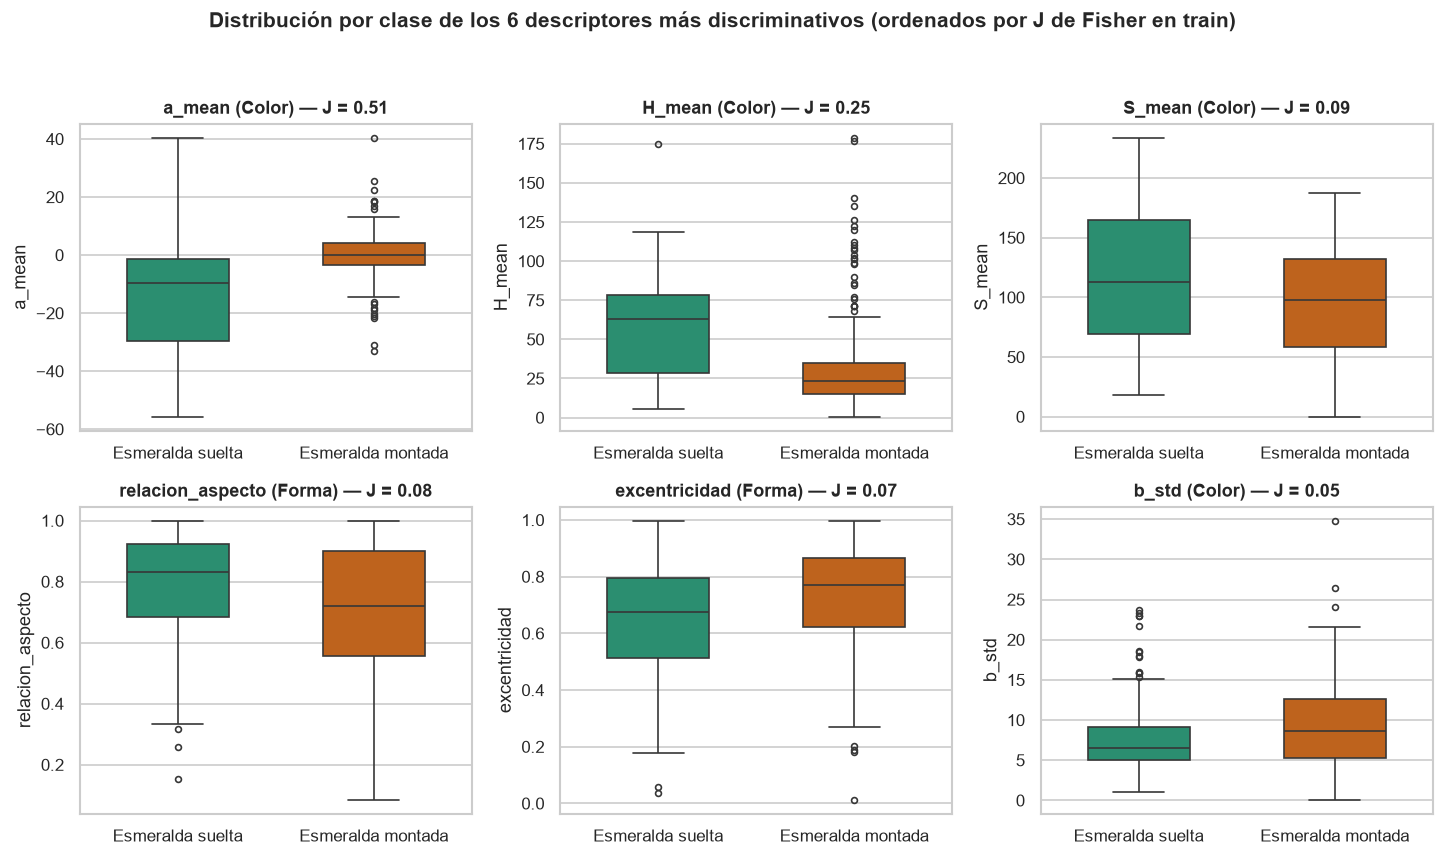

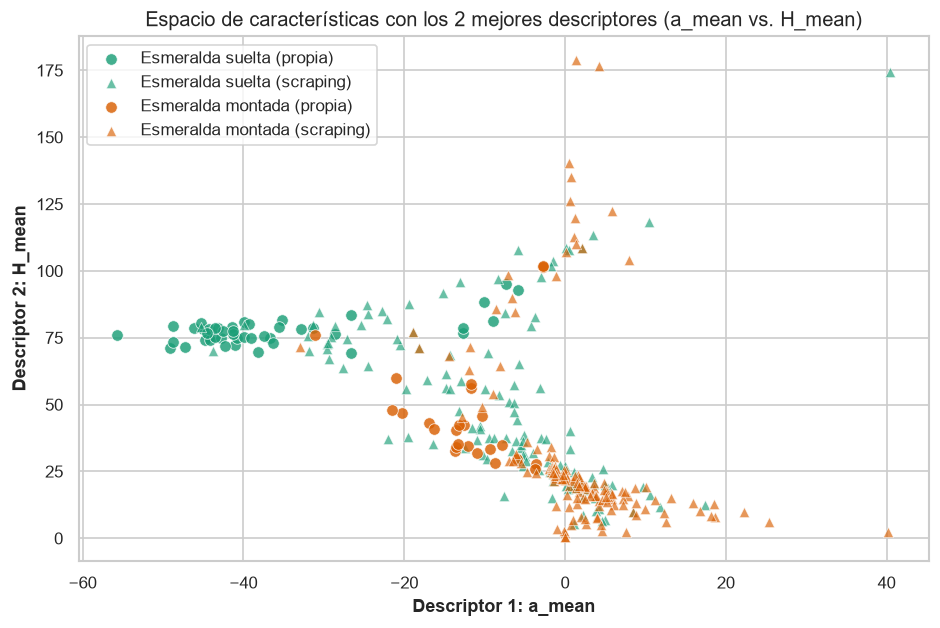

In [10]:
# Figura 6: Diagramas de caja (boxplots) de los 6 mejores descriptores
df_plot = df_feat.copy()
df_plot["Clase"] = df_plot["clase"].map(config.CLASES_NOMBRES)
paleta_nom = {config.CLASE_0_NOMBRE: PALETA_CLASES[config.CLASE_0], config.CLASE_1_NOMBRE: PALETA_CLASES[config.CLASE_1]}

fig, axes = plt.subplots(2, 3, figsize=(12.2, 7.2))
fig.suptitle(
    "Distribución por clase de los 6 descriptores más discriminativos (ordenados por J de Fisher en train)",
    fontsize=12.5,
    fontweight="bold",
    y=0.99,
)

for ax, desc in zip(axes.flatten(), TOP6_DESC):
    j_val = float(df_ranking.loc[df_ranking["descriptor"] == desc, "fisher_J"].iloc[0])
    fam = str(df_ranking.loc[df_ranking["descriptor"] == desc, "familia"].iloc[0])
    sns.boxplot(
        data=df_plot,
        x="Clase",
        y=desc,
        hue="Clase",
        palette=paleta_nom,
        legend=False,
        width=0.52,
        fliersize=3.5,
        ax=ax,
    )
    ax.set_title(f"{desc} ({fam}) — J = {j_val:.2f}", fontsize=10.5, fontweight="bold")
    ax.set_xlabel("")

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(config.FIGURAS_DIR / "fig06_boxplots_descriptores.png", bbox_inches="tight")
plt.show()

# Figura 7: Gráfico de dispersión con los 2 mejores descriptores
f1, f2 = TOP2_DESC[0], TOP2_DESC[1]
fig, ax = plt.subplots(figsize=(8.0, 5.4))
marcadores = {"propia": "o", "scraping": "^"}

for clase in config.CLASES:
    for origen in ["propia", "scraping"]:
        sub = df_feat[(df_feat["clase"] == clase) & (df_feat["origen"] == origen)]
        if len(sub) == 0:
            continue
        ax.scatter(
            sub[f1],
            sub[f2],
            c=PALETA_CLASES[clase],
            marker=marcadores[origen],
            s=48 if origen == "propia" else 38,
            alpha=0.82 if origen == "propia" else 0.65,
            edgecolors="white",
            linewidths=0.5,
            label=f"{config.CLASES_NOMBRES[clase]} ({origen})",
        )

ax.set_xlabel(f"Descriptor 1: {f1}", fontweight="bold")
ax.set_ylabel(f"Descriptor 2: {f2}", fontweight="bold")
ax.set_title(f"Espacio de características con los 2 mejores descriptores ({f1} vs. {f2})")
ax.legend(frameon=True, loc="best")
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig07_scatter_descriptores.png", bbox_inches="tight")
plt.show()

---
## 4. Clasificación y evaluación
Se comparan:
1. **Clasificador Heurístico (línea base):** Reglas `if/else` simples construidas con umbrales sobre los 2 mejores descriptores del conjunto de **entrenamiento**.
2. **Clasificador Supervisado 1 — KNN con `StandardScaler`:** Selección de `k` en `{1, 3, 5, 7, 9, 11}` mediante validación cruzada estratificada de 5 particiones en entrenamiento.
3. **Clasificador Supervisado 2 (comparativo) — SVM (RBF) con `StandardScaler`:** Selección de `C` en `{0.1, 1.0, 10.0}` en entrenamiento.

El conjunto de prueba (30 %) **nunca se emplea** para escoger descriptores, umbrales ni hiperparámetros.

=== Clasificador Heurístico (Línea base) ===
Regla elegida en TRAIN : Si a_mean > -3.963 -> Esmeralda montada; en caso contrario -> Esmeralda suelta
Exactitud en TRAIN     : 73.39%
Exactitud en TEST      : 68.22%


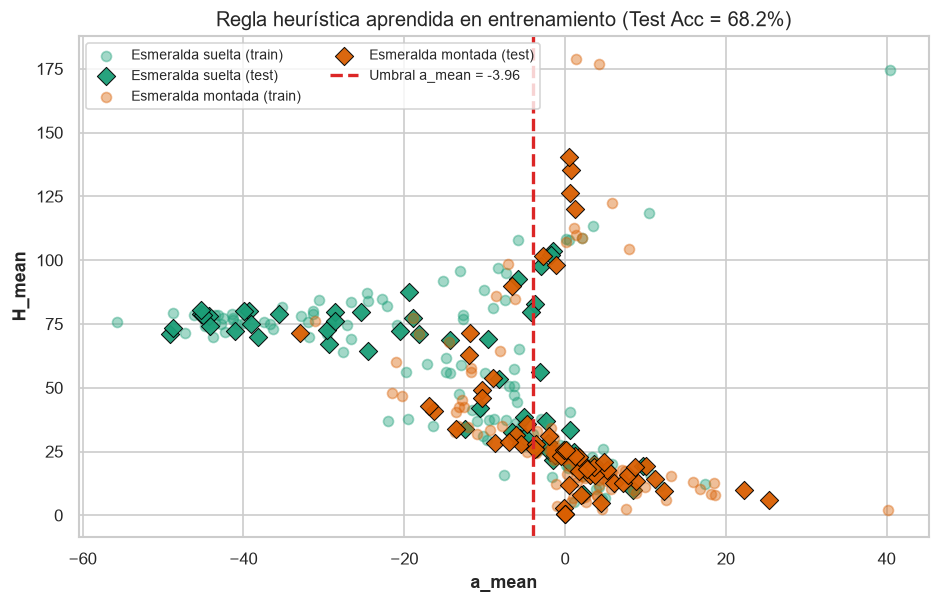

In [11]:
y_train = (train_df["clase"] == config.CLASE_1).astype(int).to_numpy()
y_test = (test_df["clase"] == config.CLASE_1).astype(int).to_numpy()
X_train = train_df[DESCRIPTOR_COLS].to_numpy(dtype=np.float64)
X_test = test_df[DESCRIPTOR_COLS].to_numpy(dtype=np.float64)

f1, f2 = TOP2_DESC[0], TOP2_DESC[1]
x1_tr = train_df[f1].to_numpy(dtype=np.float64)
x2_tr = train_df[f2].to_numpy(dtype=np.float64)
x1_te = test_df[f1].to_numpy(dtype=np.float64)
x2_te = test_df[f2].to_numpy(dtype=np.float64)

# Búsqueda de regla heurística simple (1D y 2D) estrictamente sobre TRAIN
def mejor_umbral_1d(vals, y_true):
    cand = np.unique(np.percentile(vals, np.linspace(5, 95, 91)))
    mejor_acc, mejor_t, mejor_dir = -1.0, float(np.median(vals)), ">"
    for t in cand:
        for direc in (">", "<="):
            pred = (vals > t).astype(int) if direc == ">" else (vals <= t).astype(int)
            acc = accuracy_score(y_true, pred)
            if acc > mejor_acc:
                mejor_acc, mejor_t, mejor_dir = float(acc), float(t), direc
    return mejor_t, mejor_dir, mejor_acc


t1_1d, dir1_1d, acc1_tr = mejor_umbral_1d(x1_tr, y_train)

# También evaluamos regla combinada 2D (AND / OR) con rejilla gruesa en TRAIN
c1_grid = np.unique(np.percentile(x1_tr, np.linspace(10, 90, 25)))
c2_grid = np.unique(np.percentile(x2_tr, np.linspace(10, 90, 25)))
mejor_2d = {"acc": -1.0}
for t1 in c1_grid:
    for t2 in c2_grid:
        for d1 in (">", "<="):
            cond1 = (x1_tr > t1) if d1 == ">" else (x1_tr <= t1)
            for d2 in (">", "<="):
                cond2 = (x2_tr > t2) if d2 == ">" else (x2_tr <= t2)
                for op in ("AND", "OR"):
                    pred = (cond1 & cond2).astype(int) if op == "AND" else (cond1 | cond2).astype(int)
                    acc = float(accuracy_score(y_train, pred))
                    if acc > mejor_2d["acc"]:
                        mejor_2d = {"acc": acc, "t1": float(t1), "d1": d1, "t2": float(t2), "d2": d2, "op": op}

usar_2d = (mejor_2d["acc"] - acc1_tr) >= 0.015


def predecir_heuristico(v1, v2):
    if usar_2d:
        c1 = (v1 > mejor_2d["t1"]) if mejor_2d["d1"] == ">" else (v1 <= mejor_2d["t1"])
        c2 = (v2 > mejor_2d["t2"]) if mejor_2d["d2"] == ">" else (v2 <= mejor_2d["t2"])
        return (c1 & c2).astype(int) if mejor_2d["op"] == "AND" else (c1 | c2).astype(int)
    return (v1 > t1_1d).astype(int) if dir1_1d == ">" else (v1 <= t1_1d).astype(int)


if usar_2d:
    regla_heuristica_txt = (
        f"Si ({f1} {mejor_2d['d1']} {mejor_2d['t1']:.3f}) {mejor_2d['op']} "
        f"({f2} {mejor_2d['d2']} {mejor_2d['t2']:.3f}) -> {config.CLASE_1_NOMBRE}; "
        f"en caso contrario -> {config.CLASE_0_NOMBRE}"
    )
    heur_train_acc = mejor_2d["acc"]
else:
    regla_heuristica_txt = (
        f"Si {f1} {dir1_1d} {t1_1d:.3f} -> {config.CLASE_1_NOMBRE}; "
        f"en caso contrario -> {config.CLASE_0_NOMBRE}"
    )
    heur_train_acc = acc1_tr

y_pred_heur = predecir_heuristico(x1_te, x2_te)
heur_test_acc = float(accuracy_score(y_test, y_pred_heur))

print("=== Clasificador Heurístico (Línea base) ===")
print(f"Regla elegida en TRAIN : {regla_heuristica_txt}")
print(f"Exactitud en TRAIN     : {heur_train_acc * 100:.2f}%")
print(f"Exactitud en TEST      : {heur_test_acc * 100:.2f}%")

# Figura 8: Frontera del clasificador heurístico en espacio (f1, f2)
fig, ax = plt.subplots(figsize=(8.0, 5.2))
for clase_id, clase_key in enumerate(config.CLASES):
    mask_tr = y_train == clase_id
    mask_te = y_test == clase_id
    ax.scatter(
        x1_tr[mask_tr], x2_tr[mask_tr],
        c=PALETA_CLASES[clase_key], alpha=0.40, s=36, marker="o",
        label=f"{config.CLASES_NOMBRES[clase_key]} (train)",
    )
    ax.scatter(
        x1_te[mask_te], x2_te[mask_te],
        c=PALETA_CLASES[clase_key], alpha=0.95, s=60, marker="D", edgecolors="black", linewidths=0.6,
        label=f"{config.CLASES_NOMBRES[clase_key]} (test)",
    )

t1_plot = mejor_2d["t1"] if usar_2d else t1_1d
ax.axvline(t1_plot, color="#dc2626", linestyle="--", linewidth=2.0, label=f"Umbral {f1} = {t1_plot:.2f}")
if usar_2d:
    ax.axhline(mejor_2d["t2"], color="#7c3aed", linestyle="-.", linewidth=2.0, label=f"Umbral {f2} = {mejor_2d['t2']:.2f}")

ax.set_xlabel(f1, fontweight="bold")
ax.set_ylabel(f2, fontweight="bold")
ax.set_title(f"Regla heurística aprendida en entrenamiento (Test Acc = {heur_test_acc*100:.1f}%)")
ax.legend(loc="best", ncol=2, fontsize=8.5, frameon=True)
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig08_frontera_heuristico.png", bbox_inches="tight")
plt.show()

=== Validación cruzada 5-fold en TRAIN (KNN) ===


,k,cv_mean,cv_std
0,1,0.741796,0.047479
1,3,0.741796,0.030787
2,5,0.765959,0.038175
3,7,0.769878,0.056080
4,9,0.749878,0.048993
5,11,0.754041,0.049605


Mejor k seleccionado en TRAIN: k = 7 (CV Acc = 76.99%)
Mejor SVM (RBF) en TRAIN    : C = 1.0 (CV Acc = 78.22%)


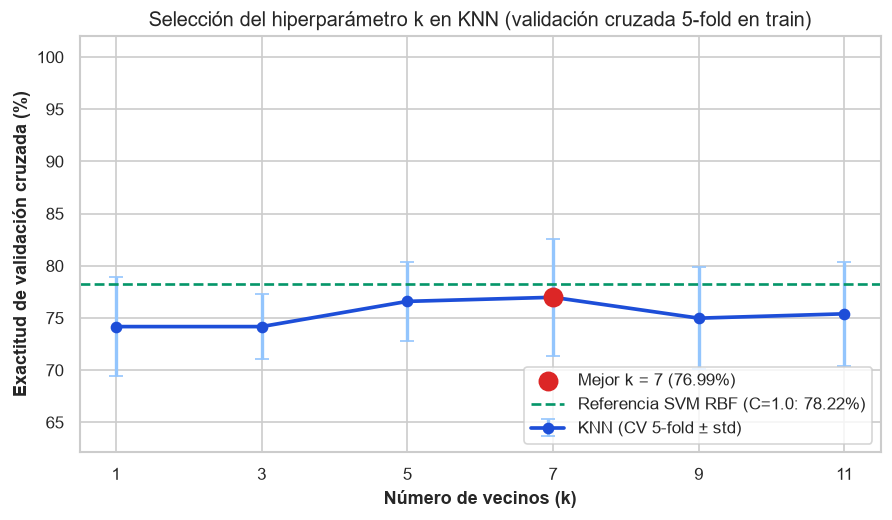

In [12]:
# Clasificador Supervisado: StandardScaler + KNN (CV 5-fold en train) y comparación con SVM
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

knn_cv_resultados = []
for k in config.KNN_K_VALUES:
    pipe_knn = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    scores = cross_val_score(pipe_knn, X_train, y_train, cv=cv, scoring="accuracy")
    knn_cv_resultados.append(
        {"k": int(k), "cv_mean": float(scores.mean()), "cv_std": float(scores.std())}
    )

df_knn_cv = pd.DataFrame(knn_cv_resultados)
best_knn_row = df_knn_cv.sort_values(["cv_mean", "k"], ascending=[False, True]).iloc[0]
best_k = int(best_knn_row["k"])

modelo_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k)),
])
modelo_knn.fit(X_train, y_train)
y_pred_knn = modelo_knn.predict(X_test)

# Comparación opcional con SVM (RBF) + StandardScaler
svm_cv_resultados = []
for c_val in config.SVM_C_VALUES:
    pipe_svm = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="rbf", C=c_val, gamma="scale", random_state=config.RANDOM_STATE)),
    ])
    scores = cross_val_score(pipe_svm, X_train, y_train, cv=cv, scoring="accuracy")
    svm_cv_resultados.append(
        {"C": float(c_val), "cv_mean": float(scores.mean()), "cv_std": float(scores.std())}
    )

df_svm_cv = pd.DataFrame(svm_cv_resultados)
best_svm_row = df_svm_cv.sort_values("cv_mean", ascending=False).iloc[0]
best_c = float(best_svm_row["C"])

modelo_svm = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", C=best_c, gamma="scale", random_state=config.RANDOM_STATE)),
])
modelo_svm.fit(X_train, y_train)
y_pred_svm = modelo_svm.predict(X_test)

print("=== Validación cruzada 5-fold en TRAIN (KNN) ===")
display(df_knn_cv)
print(f"Mejor k seleccionado en TRAIN: k = {best_k} (CV Acc = {best_knn_row['cv_mean']*100:.2f}%)")
print(f"Mejor SVM (RBF) en TRAIN    : C = {best_c} (CV Acc = {best_svm_row['cv_mean']*100:.2f}%)")

# Figura 9: Selección de k en KNN mediante validación cruzada
fig, ax = plt.subplots(figsize=(7.6, 4.5))
ax.errorbar(
    df_knn_cv["k"],
    df_knn_cv["cv_mean"] * 100.0,
    yerr=df_knn_cv["cv_std"] * 100.0,
    fmt="-o",
    color="#1d4ed8",
    ecolor="#93c5fd",
    elinewidth=2.0,
    capsize=4,
    linewidth=2.2,
    label="KNN (CV 5-fold ± std)",
)
ax.scatter(
    [best_k],
    [best_knn_row["cv_mean"] * 100.0],
    color="#dc2626",
    s=120,
    zorder=5,
    label=f"Mejor k = {best_k} ({best_knn_row['cv_mean']*100:.2f}%)",
)
ax.axhline(
    best_svm_row["cv_mean"] * 100.0,
    color="#059669",
    linestyle="--",
    linewidth=1.6,
    label=f"Referencia SVM RBF (C={best_c}: {best_svm_row['cv_mean']*100:.2f}%)",
)
ax.set_xticks(config.KNN_K_VALUES)
ax.set_xlabel("Número de vecinos (k)", fontweight="bold")
ax.set_ylabel("Exactitud de validación cruzada (%)", fontweight="bold")
ax.set_title("Selección del hiperparámetro k en KNN (validación cruzada 5-fold en train)")
ax.set_ylim(max(50, (df_knn_cv["cv_mean"].min() - 0.12) * 100), 102)
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig09_seleccion_k_knn.png", bbox_inches="tight")
plt.show()

=== Resultados comparativos en conjunto de prueba (TEST) ===


,Clasificador,Exactitud (%),Precisión (%),Sensibilidad (%),F1-score (%),Errores (test)
0,Heurístico,68.22,66.67,71.70,69.09,34
1,KNN (k=7),83.18,88.89,75.47,81.63,18
2,SVM (C=1.0),83.18,84.31,81.13,82.69,18


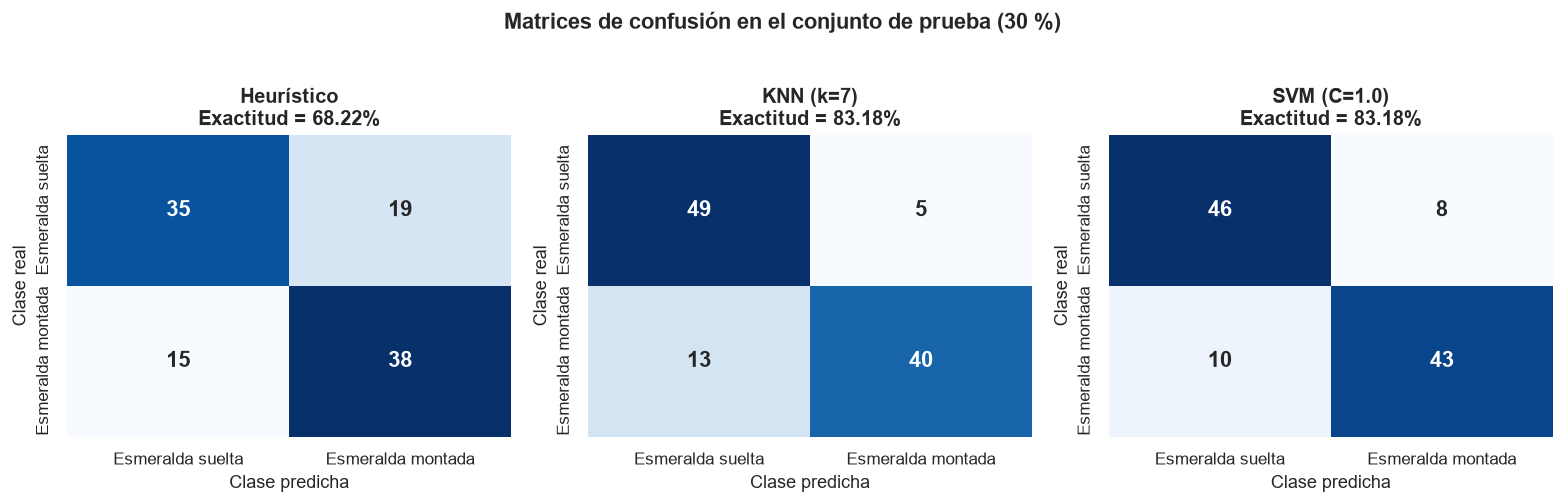


=== Desempeño en TEST desagregado por origen (Propias vs. Scraping) ===


,Clasificador,Origen,N (test),Exactitud (%),Errores
0,Heurístico,propia,21,76.19,5
1,Heurístico,scraping,86,66.28,29
2,KNN (k=7),propia,21,100.00,0
3,KNN (k=7),scraping,86,79.07,18
4,SVM (C=1.0),propia,21,100.00,0
5,SVM (C=1.0),scraping,86,79.07,18


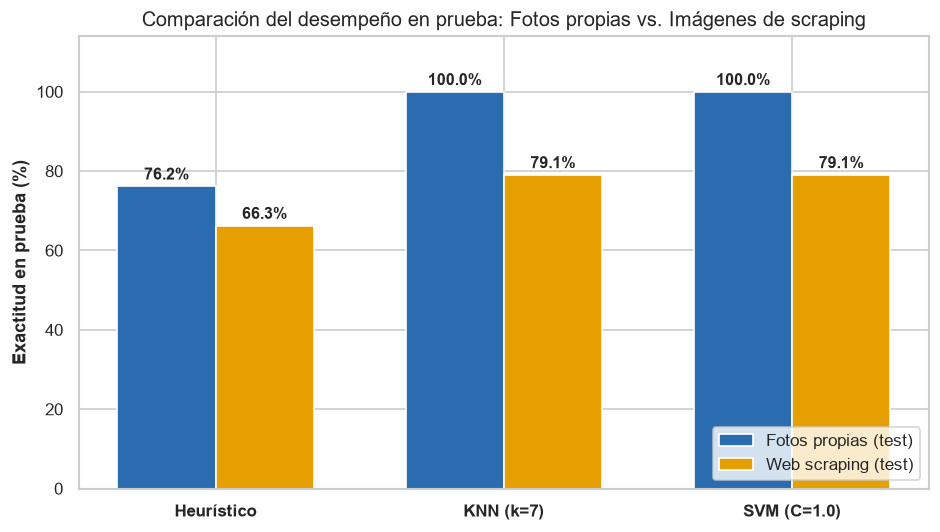

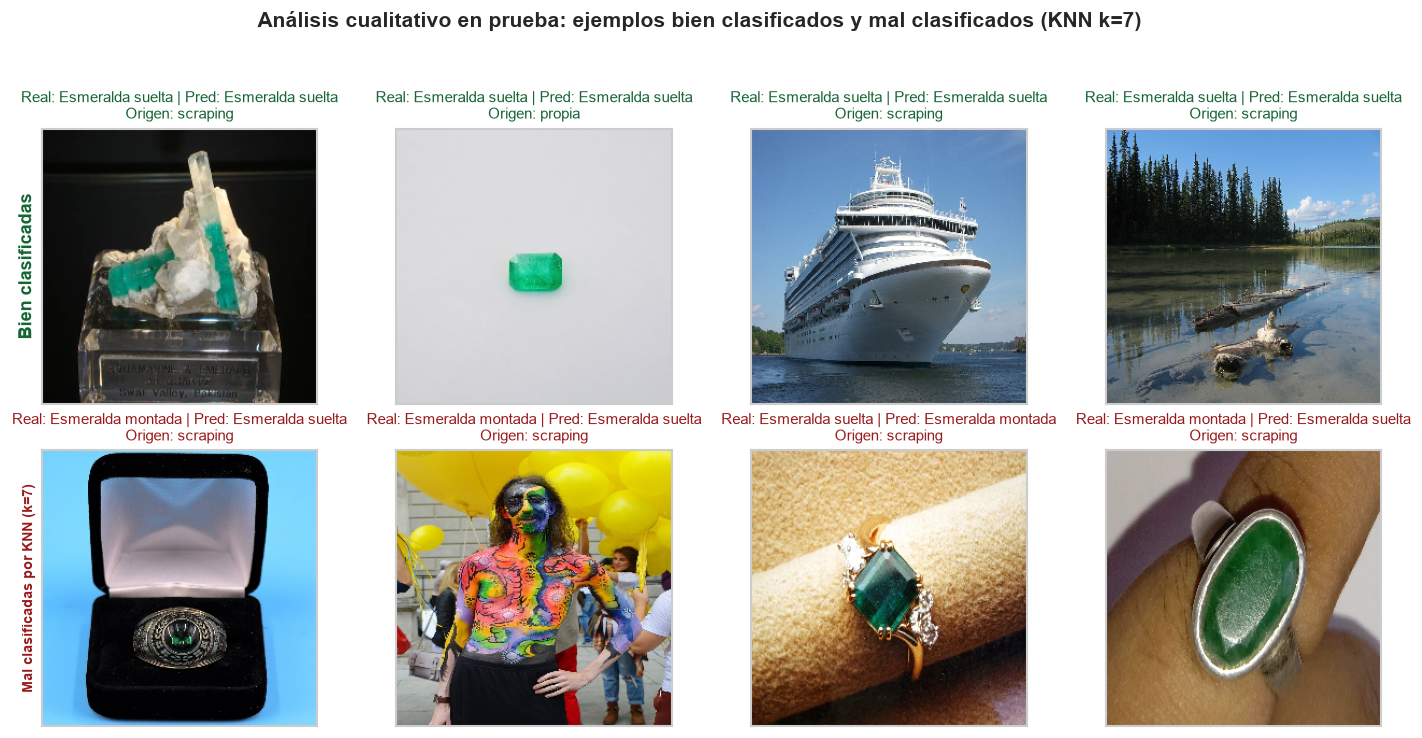

In [13]:
# Evaluación final en TEST (conjunto intacto)
def evaluar_modelo(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    return {
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "recall": round(float(recall_score(y_true, y_pred, zero_division=0)), 4),
        "f1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "confusion_matrix": cm.tolist(),
        "n_errores": int(np.sum(y_true != y_pred)),
    }


modelos_eval = {
    "Heurístico": (y_pred_heur, evaluar_modelo(y_test, y_pred_heur)),
    f"KNN (k={best_k})": (y_pred_knn, evaluar_modelo(y_test, y_pred_knn)),
    f"SVM (C={best_c})": (y_pred_svm, evaluar_modelo(y_test, y_pred_svm)),
}

tabla_res = pd.DataFrame(
    [
        {
            "Clasificador": nom,
            "Exactitud (%)": round(m["accuracy"] * 100, 2),
            "Precisión (%)": round(m["precision"] * 100, 2),
            "Sensibilidad (%)": round(m["recall"] * 100, 2),
            "F1-score (%)": round(m["f1"] * 100, 2),
            "Errores (test)": m["n_errores"],
        }
        for nom, (_, m) in modelos_eval.items()
    ]
)
print("=== Resultados comparativos en conjunto de prueba (TEST) ===")
display(tabla_res)

# Figura 10: Matrices de confusión comparadas
etiquetas_nom = [config.CLASE_0_NOMBRE, config.CLASE_1_NOMBRE]
fig, axes = plt.subplots(1, 3, figsize=(13.2, 4.1))
fig.suptitle("Matrices de confusión en el conjunto de prueba (30 %)", fontsize=13, fontweight="bold", y=1.02)

for ax, (nom, (_, met)) in zip(axes, modelos_eval.items()):
    cm = np.array(met["confusion_matrix"])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=etiquetas_nom,
        yticklabels=etiquetas_nom,
        annot_kws={"size": 13, "weight": "bold"},
        ax=ax,
    )
    ax.set_title(f"{nom}\nExactitud = {met['accuracy']*100:.2f}%", fontweight="bold")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")

plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig10_matrices_confusion.png", bbox_inches="tight")
plt.show()

# Comparación explícita: desempeño en fotos propias vs. imágenes de scraping (TEST)
comparacion_origen = {}
filas_orig = []
for nom, (preds, _) in modelos_eval.items():
    comparacion_origen[nom] = {}
    for orig in ["propia", "scraping"]:
        idx_orig = (test_df["origen"] == orig).to_numpy()
        n_sub = int(idx_orig.sum())
        if n_sub > 0:
            acc_sub = float(accuracy_score(y_test[idx_orig], preds[idx_orig]))
            err_sub = int(np.sum(y_test[idx_orig] != preds[idx_orig]))
        else:
            acc_sub, err_sub = 0.0, 0
        comparacion_origen[nom][orig] = {
            "n": n_sub,
            "accuracy": round(acc_sub, 4),
            "errores": err_sub,
        }
        filas_orig.append(
            {
                "Clasificador": nom,
                "Origen": orig,
                "N (test)": n_sub,
                "Exactitud (%)": round(acc_sub * 100, 2),
                "Errores": err_sub,
            }
        )

df_orig_eval = pd.DataFrame(filas_orig)
print("\n=== Desempeño en TEST desagregado por origen (Propias vs. Scraping) ===")
display(df_orig_eval)

# Figura 12: Gráfica comparativa Propias vs. Scraping
fig, ax = plt.subplots(figsize=(8.0, 4.6))
nombres_clf = list(modelos_eval.keys())
x = np.arange(len(nombres_clf))
w = 0.34
acc_prop = [comparacion_origen[n]["propia"]["accuracy"] * 100.0 for n in nombres_clf]
acc_scrap = [comparacion_origen[n]["scraping"]["accuracy"] * 100.0 for n in nombres_clf]

b1 = ax.bar(x - w / 2, acc_prop, w, label="Fotos propias (test)", color=PALETA_ORIGEN["propia"])
b2 = ax.bar(x + w / 2, acc_scrap, w, label="Web scraping (test)", color=PALETA_ORIGEN["scraping"])
for bars in (b1, b2):
    for bar in bars:
        h_val = bar.get_height()
        ax.annotate(
            f"{h_val:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, h_val),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontweight="bold",
            fontsize=9.5,
        )

ax.set_xticks(x)
ax.set_xticklabels(nombres_clf, fontweight="bold")
ax.set_ylabel("Exactitud en prueba (%)", fontweight="bold")
ax.set_ylim(0, 114)
ax.set_title("Comparación del desempeño en prueba: Fotos propias vs. Imágenes de scraping")
ax.legend(loc="lower right", frameon=True)
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig12_propias_vs_scraping.png", bbox_inches="tight")
plt.show()

# Figura 11: Ejemplos reales bien clasificados y mal clasificados (usando KNN principal)
test_eval = test_df.copy()
test_eval["y_true"] = y_test
test_eval["y_pred_knn"] = y_pred_knn
test_eval["y_pred_heur"] = y_pred_heur
test_eval["acierto_knn"] = test_eval["y_true"] == test_eval["y_pred_knn"]

aciertos_df = test_eval[test_eval["acierto_knn"]]
errores_df = test_eval[~test_eval["acierto_knn"]]

# Si KNN tuvo 0 errores en test, mostramos los errores del heurístico como casos difíciles
fuente_err_label = f"Mal clasificadas por KNN (k={best_k})"
if len(errores_df) == 0:
    errores_df = test_eval[test_eval["y_true"] != test_eval["y_pred_heur"]]
    fuente_err_label = "Sin errores en KNN — casos erróneos del Heurístico"

n_ej = 4
muestra_ok = aciertos_df.sample(n=min(n_ej, len(aciertos_df)), random_state=config.RANDOM_STATE)
muestra_err = errores_df.head(n_ej)

fig, axes = plt.subplots(2, n_ej, figsize=(12.2, 6.2))
fig.suptitle(
    f"Análisis cualitativo en prueba: ejemplos bien clasificados y mal clasificados (KNN k={best_k})",
    fontsize=12.5,
    fontweight="bold",
    y=0.99,
)

for c in range(n_ej):
    # Fila 0: Bien clasificadas
    ax_ok = axes[0, c]
    if c < len(muestra_ok):
        r_ok = muestra_ok.iloc[c]
        im = cv2.imread(str(config.DATASET_DIR / r_ok["filename"]))
        if im is not None:
            ax_ok.imshow(cv2.cvtColor(cv2.resize(im, (256, 256)), cv2.COLOR_BGR2RGB))
        real_n = etiquetas_nom[int(r_ok["y_true"])]
        pred_n = etiquetas_nom[int(r_ok["y_pred_knn"])]
        ax_ok.set_title(f"Real: {real_n} | Pred: {pred_n}\nOrigen: {r_ok['origen']}", fontsize=9, color="#166534")
    ax_ok.set_xticks([])
    ax_ok.set_yticks([])
    if c == 0:
        ax_ok.set_ylabel("Bien clasificadas", fontweight="bold", color="#166534")

    # Fila 1: Mal clasificadas
    ax_er = axes[1, c]
    if c < len(muestra_err):
        r_er = muestra_err.iloc[c]
        im = cv2.imread(str(config.DATASET_DIR / r_er["filename"]))
        if im is not None:
            ax_er.imshow(cv2.cvtColor(cv2.resize(im, (256, 256)), cv2.COLOR_BGR2RGB))
        real_n = etiquetas_nom[int(r_er["y_true"])]
        pred_col = "y_pred_knn" if len(test_eval[~test_eval["acierto_knn"]]) > 0 else "y_pred_heur"
        pred_n = etiquetas_nom[int(r_er[pred_col])]
        ax_er.set_title(f"Real: {real_n} | Pred: {pred_n}\nOrigen: {r_er['origen']}", fontsize=9, color="#991b1b")
    else:
        ax_er.text(0.5, 0.5, "Sin más errores", ha="center", va="center", fontsize=9, color="gray")
    ax_er.set_xticks([])
    ax_er.set_yticks([])
    if c == 0:
        ax_er.set_ylabel(fuente_err_label, fontweight="bold", color="#991b1b", fontsize=8.5)

plt.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(config.FIGURAS_DIR / "fig11_ejemplos_clasificacion.png", bbox_inches="tight")
plt.show()

---
## 5. Iteraciones experimentales y estudio de ablación (sobre entrenamiento)
Para respaldar cada decisión del diseño con evidencia experimental reproducible (sin tocar el conjunto de prueba), se ejecutan tres iteraciones sistemáticas:
1. **Iteración de filtrado espacial:** Sin filtro vs. Gaussiano (`5x5`) vs. Mediana (`5x5`) evaluando estabilidad de la segmentación.
2. **Iteración de ablación de descriptores (CV 5-fold en train):** Solo Color, Solo Forma, Solo Textura, Color + Forma y Combinado (18 descriptores).
3. **Iteración de clasificadores clásicos (`scikit-learn`):** Comparación en CV 5-fold de KNN, SVM (RBF) y MLP (`MLPClassifier`, 1 capa oculta, con `StandardScaler`).

=== Iteración 1: Estabilidad de segmentación según filtro espacial ===


,filtro,componentes_otsu_promedio,solidez_media
0,Sin filtro,136.21,0.7106
1,Gaussiano 5x5,42.75,0.7480
2,Mediana 5x5,34.33,0.7384



=== Iteración 2: Estudio de ablación por familias de descriptores (CV en train) ===


,subconjunto,n_descriptores,cv_mean,cv_std
0,Solo Color (8),8,0.7420,0.0384
1,Solo Forma (5),5,0.5564,0.0595
2,Solo Textura (5),5,0.5569,0.0713
3,Color + Forma (13),13,0.7458,0.0496
4,Todas las familias (18),18,0.7699,0.0561



=== Iteración 3: MLP (32 neuronas ocultas) ===
  CV 5-fold (train): 79.84% ± 3.80%
  Exactitud en TEST: 82.24% (19 errores)


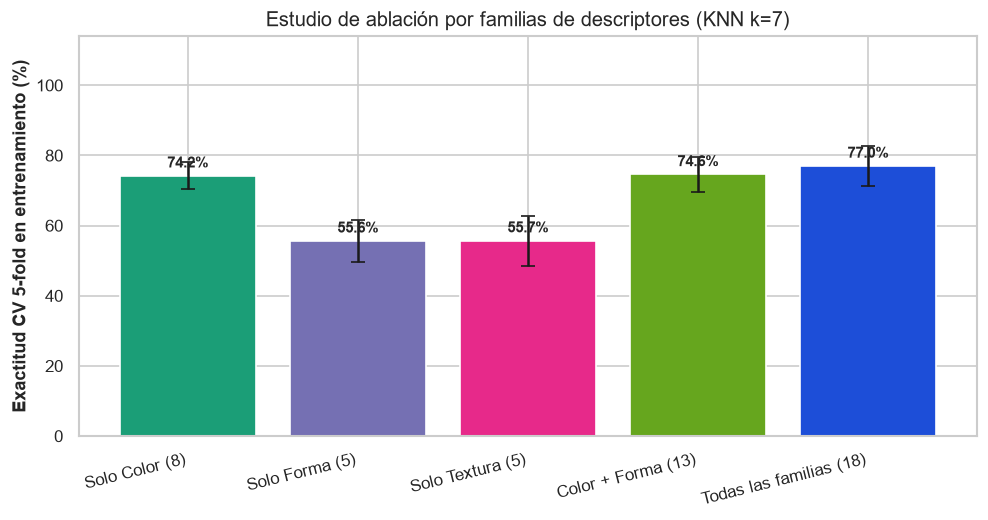

In [14]:
# --- Iteración 1: Comparación de filtrado espacial sobre una muestra de entrenamiento ---
muestra_iter = train_df.sample(n=min(24, len(train_df)), random_state=config.RANDOM_STATE)
filtros_iter = []
for nombre_f in ["Sin filtro", "Gaussiano 5x5", "Mediana 5x5"]:
    comp_otsu, sol_vals = [], []
    for _, r in muestra_iter.iterrows():
        im = cv2.imread(str(config.DATASET_DIR / r["filename"]))
        if im is None:
            continue
        im_eq = aplicar_clahe_lab(redimensionar_estandar(im, config.IMG_SIZE))
        if nombre_f == "Gaussiano 5x5":
            im_f = aplicar_filtro_gaussiano(im_eq)
        elif nombre_f == "Mediana 5x5":
            im_f = cv2.medianBlur(im_eq, 5)
        else:
            im_f = im_eq
        _, _, _, m_otsu = segmentar_otsu_lab_hsv(im_f)
        _, _, _, cnt = limpiar_mascara_morfologia(m_otsu)
        comp_otsu.append(cv2.connectedComponents(m_otsu)[0] - 1)
        hull_a = cv2.contourArea(cv2.convexHull(cnt))
        sol_vals.append(cv2.contourArea(cnt) / hull_a if hull_a > 1e-6 else 0.0)
    filtros_iter.append(
        {
            "filtro": nombre_f,
            "componentes_otsu_promedio": round(float(np.mean(comp_otsu)), 2),
            "solidez_media": round(float(np.mean(sol_vals)), 4),
        }
    )

df_iter_filtros = pd.DataFrame(filtros_iter)
print("=== Iteración 1: Estabilidad de segmentación según filtro espacial ===")
display(df_iter_filtros)

# --- Iteración 2: Ablación por familias de descriptores (CV 5-fold en TRAIN con KNN) ---
subconjuntos_desc = {
    "Solo Color (8)": FAMILIAS_DESCRIPTORES["Color"],
    "Solo Forma (5)": FAMILIAS_DESCRIPTORES["Forma"],
    "Solo Textura (5)": FAMILIAS_DESCRIPTORES["Textura"],
    "Color + Forma (13)": FAMILIAS_DESCRIPTORES["Color"] + FAMILIAS_DESCRIPTORES["Forma"],
    "Todas las familias (18)": DESCRIPTOR_COLS,
}
ablacion_rows = []
for nombre_sub, cols_sub in subconjuntos_desc.items():
    X_sub = train_df[cols_sub].to_numpy(dtype=np.float64)
    pipe_ab = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=best_k)),
    ])
    sc = cross_val_score(pipe_ab, X_sub, y_train, cv=cv, scoring="accuracy")
    ablacion_rows.append(
        {
            "subconjunto": nombre_sub,
            "n_descriptores": len(cols_sub),
            "cv_mean": round(float(sc.mean()), 4),
            "cv_std": round(float(sc.std()), 4),
        }
    )

df_ablacion = pd.DataFrame(ablacion_rows)
print("\n=== Iteración 2: Estudio de ablación por familias de descriptores (CV en train) ===")
display(df_ablacion)

# --- Iteración 3: Comparación adicional con MLP (scikit-learn) en CV 5-fold ---
pipe_mlp = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(32,), max_iter=500, random_state=config.RANDOM_STATE)),
])
mlp_cv_scores = cross_val_score(pipe_mlp, X_train, y_train, cv=cv, scoring="accuracy")
pipe_mlp.fit(X_train, y_train)
y_pred_mlp = pipe_mlp.predict(X_test)
mlp_test_met = evaluar_modelo(y_test, y_pred_mlp)
print(
    f"\n=== Iteración 3: MLP (32 neuronas ocultas) ===\n"
    f"  CV 5-fold (train): {mlp_cv_scores.mean()*100:.2f}% ± {mlp_cv_scores.std()*100:.2f}%\n"
    f"  Exactitud en TEST: {mlp_test_met['accuracy']*100:.2f}% ({mlp_test_met['n_errores']} errores)"
)

# Guardar tabla de iteraciones y gráfica de ablación
df_ablacion.to_csv(config.RESULTADOS_DIR / "experimentos_iteraciones.csv", index=False, encoding="utf-8")

fig, ax = plt.subplots(figsize=(8.4, 4.5))
barras = ax.bar(
    df_ablacion["subconjunto"],
    df_ablacion["cv_mean"] * 100.0,
    yerr=df_ablacion["cv_std"] * 100.0,
    capsize=4,
    color=["#1b9e77", "#7570b3", "#e7298a", "#66a61e", "#1d4ed8"],
)
for b in barras:
    h_v = b.get_height()
    ax.annotate(f"{h_v:.1f}%", xy=(b.get_x() + b.get_width() / 2, h_v), xytext=(0, 5), textcoords="offset points", ha="center", fontweight="bold", fontsize=9)
ax.set_ylabel("Exactitud CV 5-fold en entrenamiento (%)", fontweight="bold")
ax.set_title(f"Estudio de ablación por familias de descriptores (KNN k={best_k})")
ax.set_ylim(0, 114)
plt.xticks(rotation=14, ha="right")
plt.tight_layout()
fig.savefig(config.FIGURAS_DIR / "fig13_ablacion_iteraciones.png", bbox_inches="tight")
plt.show()

In [15]:
# Exportar todas las métricas reales a resultados/metricas.json para el generador del informe
curacion_log = {}
if config.CURACION_LOG_JSON.exists():
    curacion_log = json.loads(config.CURACION_LOG_JSON.read_text(encoding="utf-8"))

casos_error_knn = []
for _, r in test_eval[~test_eval["acierto_knn"]].iterrows():
    casos_error_knn.append(
        {
            "filename": str(r["filename"]),
            "clase_real": etiquetas_nom[int(r["y_true"])],
            "clase_predicha": etiquetas_nom[int(r["y_pred_knn"])],
            "origen": str(r["origen"]),
        }
    )

conteo_detallado = {}
for c in config.CLASES:
    sub_c = df_feat[df_feat["clase"] == c]
    conteo_detallado[c] = {
        "nombre": config.CLASES_NOMBRES[c],
        "propia": int((sub_c["origen"] == "propia").sum()),
        "scraping": int((sub_c["origen"] == "scraping").sum()),
        "total": int(len(sub_c)),
    }

metricas_export = {
    "clases": {
        "clase_0": config.CLASE_0,
        "clase_0_nombre": config.CLASE_0_NOMBRE,
        "clase_1": config.CLASE_1,
        "clase_1_nombre": config.CLASE_1_NOMBRE,
    },
    "dataset": {
        "total_imagenes": int(len(df_feat)),
        "total_propias": int((df_feat["origen"] == "propia").sum()),
        "total_scraping": int((df_feat["origen"] == "scraping").sum()),
        "ratio_balance": float(ratio_balance),
        "por_clase": conteo_detallado,
        "n_train": int(len(train_df)),
        "n_test": int(len(test_df)),
        "modo_estratificacion": modo_estratificacion,
    },
    "curacion": curacion_log,
    "alternativa_descartada": comp_stats,
    "descriptores": {
        "total": len(DESCRIPTOR_COLS),
        "familias": FAMILIAS_DESCRIPTORES,
        "top_6": TOP6_DESC,
        "top_2": TOP2_DESC,
        "ranking_fisher": df_ranking.to_dict(orient="records"),
    },
    "clasificadores": {
        "heuristico": {
            "regla": regla_heuristica_txt,
            "usar_2d": bool(usar_2d),
            "train_accuracy": round(float(heur_train_acc), 4),
            "test": modelos_eval["Heurístico"][1],
        },
        "knn": {
            "best_k": int(best_k),
            "cv_resultados": knn_cv_resultados,
            "best_cv_accuracy": round(float(best_knn_row["cv_mean"]), 4),
            "test": modelos_eval[f"KNN (k={best_k})"][1],
        },
        "svm": {
            "best_C": float(best_c),
            "cv_resultados": svm_cv_resultados,
            "best_cv_accuracy": round(float(best_svm_row["cv_mean"]), 4),
            "test": modelos_eval[f"SVM (C={best_c})"][1],
        },
    },
    "comparacion_origen_test": {
        "heuristico": comparacion_origen["Heurístico"],
        "knn": comparacion_origen[f"KNN (k={best_k})"],
        "svm": comparacion_origen[f"SVM (C={best_c})"],
    },
    "errores_knn_test": casos_error_knn,
    "iteraciones": {
        "filtros_espaciales": filtros_iter,
        "ablacion_descriptores": ablacion_rows,
        "mlp": {
            "cv_mean": round(float(mlp_cv_scores.mean()), 4),
            "cv_std": round(float(mlp_cv_scores.std()), 4),
            "test": mlp_test_met,
        },
    },
}

with config.METRICAS_JSON.open("w", encoding="utf-8") as f_out:
    json.dump(metricas_export, f_out, ensure_ascii=False, indent=2)

print(f"Métricas exportadas exitosamente a: {config.METRICAS_JSON}")
print("=== RESUMEN EJECUTIVO ===")
print(f"  Heurístico  -> Test Acc: {metricas_export['clasificadores']['heuristico']['test']['accuracy']*100:.2f}%")
print(f"  KNN (k={best_k:<2})  -> Test Acc: {metricas_export['clasificadores']['knn']['test']['accuracy']*100:.2f}%")
print(f"  SVM (C={best_c}) -> Test Acc: {metricas_export['clasificadores']['svm']['test']['accuracy']*100:.2f}%")

Métricas exportadas exitosamente a: C:\Users\Juan.Escobar\Desktop\Vision artificial\resultados\metricas.json
=== RESUMEN EJECUTIVO ===
  Heurístico  -> Test Acc: 68.22%
  KNN (k=7 )  -> Test Acc: 83.18%
  SVM (C=1.0) -> Test Acc: 83.18%
